# E-L: sensitivity to working number of signals

100 paired linear-model trials; true L*=4 and changes at 0.20, 0.50, 0.80. Working $\hat{L}=1,\ldots,6$; fixed-$\hat{L}$ unpenalized WERM least squares, no CV or truth passed to estimator. Because this is exact fixed-L, count=L-1 and L=1 is always empty. Conditional Hausdorff omits empty fits; unconditional loss explicitly charges empty and count mismatch. From the saved 100 paired trials, the mean/median conditional Hausdorff errors are $L=2$: $0.310/0.304$, $L=3$: $0.234/0.236$, $L=4$: $0.049/0.038$, $L=5$: $0.060/0.053$, and $L=6$: $0.125/0.128$ (undefined for empty $L=1$ fits). Thus both the Mean conditional Hausdorff and the median conditional Hausdorff are minimized at $L=4$. The saved artifact retains conditional population-risk calculations only at matched L=4, not a finite-sample or misspecification guarantee. Set WERM_SMOKE=1 to run two paired trials before full execution.

### Paper-ready experiment description

Across 100 paired Monte Carlo trials (base seed 20260916), we generated $n=500$ observations with $p=100$ covariates, $x_i\sim N(0,I_p/n)$ and $y_i=x_i^\top\beta_{s(i)}+\varepsilon_i$, where $\varepsilon_i\sim N(0,0.5^2)$. The true $L^*=4$ regimes change at fractional locations $(0.20,0.50,0.80)$; the initial coefficient vector is $N(0,(n/p)I_p)$ and independent successive jumps are $N(0,1.5^2(n/p)I_p)$. On the same data in each trial, we fit fixed-$L$ unpenalized least-squares WERM for $L\in\{1,2,3,4,5,6\}$ with minimum change-point gap $\Delta_n=1$, half-squared-error loss, and the package's analytic signal weights $\pi_i^{(\ell)}=\binom{L-1}{\ell}(i/n)^\ell(1-i/n)^{L-1-\ell}$ ($i=1,\ldots,n$; $\ell=0,\ldots,L-1$). Each fit selects exactly $L-1$ changes without cross-validation; we record selected count, empty-fit rate, conditional Hausdorff error divided by $n$, unconditional location-and-count loss, and runtime. Conditional population-risk calculations are retained only for the correctly specified $L=4$ fit.


In [1]:

import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
from pathlib import Path
from time import perf_counter
import pickle
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, parallel_config
from scipy.special import comb
from WERM.estimators import weighted_erm
from WERM.gof import chgpt_gof_dp

plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({
    "font.family": "serif", "font.size": 13, "axes.labelsize": 16,
    "axes.titlesize": 17, "legend.fontsize": 12,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
})
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
SMOKE_MODE = os.environ.get("WERM_SMOKE") == "1"
N_TRIALS = 2 if SMOKE_MODE else 100
N_JOBS = 2 if SMOKE_MODE else 36
SEED = 20260916
P = 100
N = 500
NOISE_SD = 0.5
M = lambda prediction, truth: 0.5 * (np.asarray(prediction) - np.asarray(truth)) ** 2

def make_paired_data(trial, true_cp):
    """Identical X, y and signals across methods within trial."""
    rng = np.random.default_rng(np.random.SeedSequence([SEED, trial]))
    delta = N / P
    beta = np.empty((P, len(true_cp) + 1))
    beta[:, 0] = rng.normal(size=P) * np.sqrt(delta)
    for segment in range(1, beta.shape[1]):
        beta[:, segment] = beta[:, segment - 1] + 1.5 * np.sqrt(delta) * rng.normal(size=P)
    X = rng.normal(size=(N, P)) / np.sqrt(N)
    signal = np.searchsorted(true_cp, np.arange(N), side="right")
    y = np.einsum("ij,ij->i", X, beta[:, signal].T) + rng.normal(0, NOISE_SD, N)
    return X, y, beta, signal

def error_metrics(cp, truth):
    """Normalized symmetric nearest-neighbor loss, defined even at the empty set.

    U(A,B) = 0.5*[mean_a min_b |a-b|/n + mean_b min_a |a-b|/n]
             + 0.25*||A|-|B||/max(1,|A|,|B|).
    Missing-direction distance is 1. Hausdorff is reported only for nonempty B.
    """
    a, b = np.asarray(truth, int), np.asarray(cp, int)
    if b.size:
        pair = np.abs(a[:, None] - b[None, :]) / N
        directed_a = float(pair.min(axis=1).mean())
        directed_b = float(pair.min(axis=0).mean())
        haus = float(max(pair.min(axis=1).max(), pair.min(axis=0).max()))
    else:
        directed_a = directed_b = 1.0
        haus = np.nan
    count_penalty = 0.25 * abs(len(a) - len(b)) / max(1, len(a), len(b))
    return dict(count=len(b), empty=(len(b) == 0),
                conditional_haus=haus,
                exact_count_haus=haus if len(a) == len(b) else np.nan,
                unconditional_loss=0.5 * (directed_a + directed_b) + count_penalty)

def conditional_coefficient_mse(X, beta, true_signal, phi):
    """Exact E_noise[mean((B_hat-B_true)^2) | X,B_true] for this weighted LS fit.

    B_hat_l = A_l y, A_l=(X'W_l X)^(-1) X'W_l. Thus the conditional
    expectation is squared bias plus noise_sd^2 * ||A_l||_F^2. This is an
    exact finite-sample coefficient prediction, not a CP-risk theorem.
    """
    from scipy.linalg import cho_factor, cho_solve
    mu = np.einsum("ij,ij->i", X, beta[:, true_signal].T)
    total = 0.0
    for l, weight in enumerate(phi):
        w = weight / weight.sum()
        gram = X.T @ (w[:, None] * X)
        right = X.T * w
        try:
            A = cho_solve(cho_factor(gram, lower=True, check_finite=False),
                          right, check_finite=False)
        except np.linalg.LinAlgError:
            A = np.linalg.pinv(gram) @ right
        bias = A @ mu - beta[:, l]
        total += float(bias @ bias + NOISE_SD**2 * np.sum(A*A))
    return total / beta.shape[0] / beta.shape[1]

def population_prediction(beta, true_signal, phi, delta_n):
    """Conditional population-risk comparator for the *same* weighted fixed-L ERM.

    With X_i~N(0,I/n), E[w_i (y_i-X_i b)^2] is minimized at
    b_l = sum_i phi[l,i] beta_{s(i)} / sum_i phi[l,i].
    The expected per-time GOF is 0.5*(noise_sd^2+||beta_s-b_l||^2/n).
    This is a population prediction, NOT a finite-sample theorem or fixed-point
    prediction. It uses the identical phi, L, loss, and partition search.
    """
    L = phi.shape[0]
    row_mass = phi.sum(axis=1)
    mixture = np.column_stack([
        np.bincount(true_signal, weights=phi[l], minlength=beta.shape[1]) / row_mass[l]
        for l in range(L)
    ])
    beta_pop = beta @ mixture
    risk = np.empty((N, L))
    for l in range(L):
        squared = np.sum((beta[:, true_signal].T - beta_pop[:, l])**2, axis=1) / N
        risk[:, l] = 0.5 * (NOISE_SD**2 + squared)
    result = chgpt_gof_dp(lambda column, unused: column, risk, np.zeros(N),
                          N, L, delta_n, L_is_upper_bound=False)
    return result["changepoints"], beta_pop


# E-L: fixed-L least-squares WERM, including severe under/over-specification.
TRUE_CP = np.rint(N * np.array([0.20, 0.50, 0.80])).astype(int)
TRUE_L = len(TRUE_CP) + 1
WORKING_L = np.arange(1, 7)
DELTA_N = 1  # The package's exact-L default analytic marginal branch.
ARTIFACT = RESULTS_DIR / ("E_L_fixedL_L1to6_100paired_seed20260916_smoke.pkl" if SMOKE_MODE
                          else "E_L_fixedL_L1to6_100paired_seed20260916.pkl")

def analytic_fixed_l_marginals(L):
    # Exactly the Delta_n=1 formula used inside weighted_erm (i=1,...,n).
    x = np.arange(1, N + 1) / N
    phi = np.array([comb(L-1, l) * x**l * (1-x)**(L-1-l)
                    for l in range(L)], dtype=float)
    assert np.allclose(phi.sum(axis=0), 1)
    return phi

def run_trial(trial):
    X, y, beta, signal = make_paired_data(trial, TRUE_CP)
    output = {}
    for L in WORKING_L:
        tic = perf_counter()
        cp, beta_hat = weighted_erm(
            X, y, M, L=int(L), Delta_n=DELTA_N, gamma=0.0,
            L_is_upper_bound=False, return_B_hat=True,
            coefficient_loss="least_squares", coefficient_penalty="none")
        elapsed = perf_counter() - tic
        assert len(cp) == L - 1  # exact fixed-L, not model-selection CV
        output[int(L)] = dict(cp=np.asarray(cp), runtime=elapsed,
                              **error_metrics(cp, TRUE_CP))
        if L == TRUE_L:
            phi = analytic_fixed_l_marginals(int(L))
            theory_cp, beta_pop = population_prediction(beta, signal, phi, DELTA_N)
            output[int(L)]["population_cp"] = theory_cp
            output[int(L)]["population_loss"] = error_metrics(theory_cp, TRUE_CP)["unconditional_loss"]
            output[int(L)]["coefficient_mse"] = float(np.mean((beta_hat-beta)**2))
            output[int(L)]["conditional_expected_coefficient_mse"] = (
                conditional_coefficient_mse(X, beta, signal, phi))
            output[int(L)]["population_coefficient_bias"] = float(np.mean((beta_pop-beta)**2))
    return output

with parallel_config(backend="loky", inner_max_num_threads=1):
    trials = Parallel(n_jobs=N_JOBS, verbose=10)(delayed(run_trial)(t) for t in range(N_TRIALS))
assert len(trials) == N_TRIALS
assert all(set(row) == set(WORKING_L) for row in trials)
with ARTIFACT.open("wb") as handle:
    pickle.dump(dict(trials=trials, params=dict(N=N, P=P, true_cp=TRUE_CP,
        working_L=WORKING_L, delta_n=DELTA_N, n_trials=N_TRIALS,
        n_jobs=N_JOBS, seed=SEED, theory_kind="conditional population risk; matched L=4 only")), handle)
print(f"Saved {N_TRIALS} paired trials to {ARTIFACT}")


Saved 100 paired trials to results/E_L_fixedL_L1to6_100paired_seed20260916.pkl


## Load and plot with tighter layout

This cell loads the unique saved artifact; re-running plots does not rerun trials.

E-L: 100 paired trials, n=500, p=100; artifact: results/E_L_fixedL_L1to6_100paired_seed20260916.pkl
L | count | empty rate | mean / median conditional Hausdorff | exact-count Hausdorff | unconditional loss | runtime s
1 | 0.00 | 100.00% | nan / nan | nan | 1.250 | 0.003
2 | 1.00 | 0.00% | 0.310 / 0.304 | nan | 0.273 | 0.005
3 | 2.00 | 0.00% | 0.234 / 0.236 | nan | 0.196 | 0.055
4 | 3.00 | 0.00% | 0.049 / 0.038 | 0.049 | 0.023 | 0.106
5 | 4.00 | 0.00% | 0.060 / 0.053 | nan | 0.081 | 0.153
6 | 5.00 | 0.00% | 0.125 / 0.128 | nan | 0.126 | 0.192
Conditional localization by working L-hat (mean ± SE, then trial distributions).


/tmp/ipykernel_4003179/1551600467.py:78: RuntimeWarning: Mean of empty slice
  f"{np.nanmean(conditional):.3f} / {np.nanmedian(conditional):.3f} | "
/tmp/ipykernel_4003179/1551600467.py:78: RuntimeWarning: All-NaN slice encountered
  f"{np.nanmean(conditional):.3f} / {np.nanmedian(conditional):.3f} | "


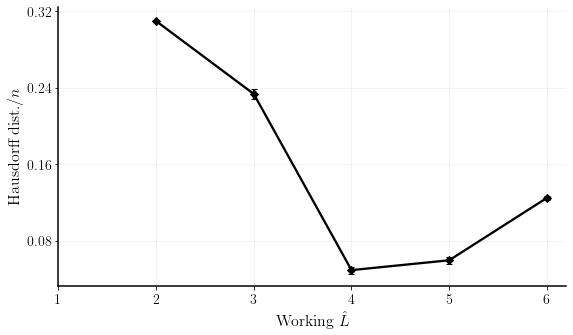

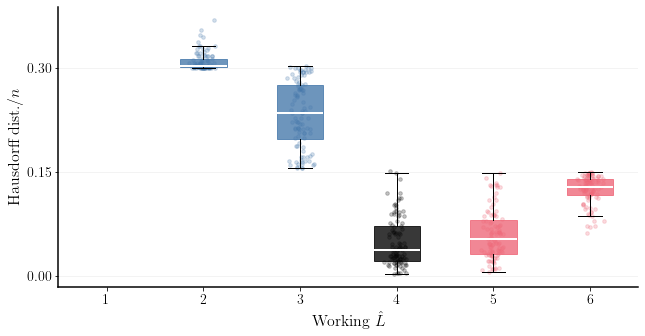

Estimated change-point locations; panels left-to-right: working L-hat = 1, 2, 3, 4, 5, 6. Dashed lines mark truth.


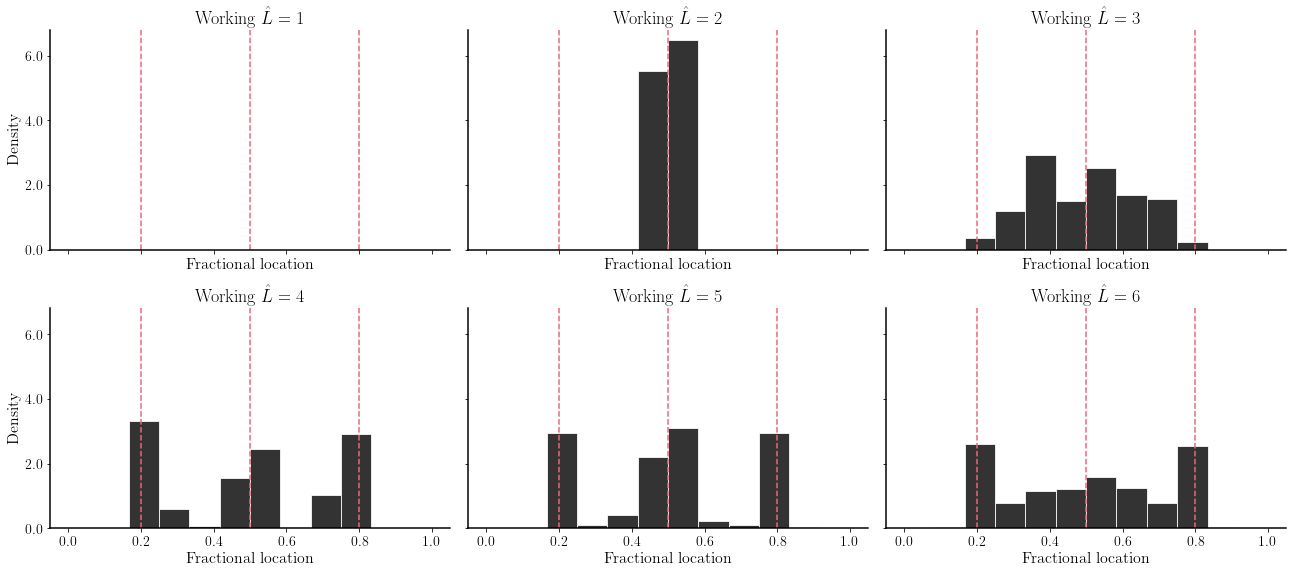

In [2]:

import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.switch_backend("module://matplotlib_inline.backend_inline")
plt.rcParams.update({
    "font.family": "serif", "font.size": 14, "axes.labelsize": 16,
    "axes.linewidth": 1.5, "axes.titlesize": 18, "legend.fontsize": 14,
    "xtick.labelsize": 14, "ytick.labelsize": 14,
    "font.serif": ["Computer Modern Roman", "Times New Roman", "DejaVu Serif"],
    "text.usetex": True,
    "lines.linewidth": 3.0, "lines.markersize": 8,
    "figure.dpi": 72, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
})
SMOKE_MODE = __import__("os").environ.get("WERM_SMOKE") == "1"

def series(trials, key, metric):
    return np.array([row[key][metric] for row in trials], dtype=float)

def mean_se(values):
    finite = np.isfinite(values)
    count = finite.sum(axis=0)
    mean = np.divide(np.nansum(values, axis=0), count,
                     out=np.full(values.shape[1], np.nan), where=count > 0)
    centered = np.where(finite, values - mean, 0)
    sd = np.sqrt(np.divide((centered**2).sum(axis=0), np.maximum(count-1, 1)))
    se = np.divide(sd, np.sqrt(count), out=np.zeros_like(sd), where=count > 0)
    return mean, se

def line_panel(ax, x, values, ylabel, color="black", theory=None):
    mean, se = mean_se(values)
    ax.errorbar(x, mean, yerr=se, color=color, marker="D", linestyle="-",
                linewidth=2.3, markersize=5, capsize=3, label="WERM")
    if theory is not None:
        ax.plot(x, theory, marker="o", linestyle="--", color="#AA3377",
                linewidth=1.7, markersize=4, label="Population")
        ax.legend(frameon=False)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=.18)

def jitter_boxes(ax, grouped, labels, ylabel, colors):
    rng = np.random.default_rng(2901)
    positions = np.arange(1, len(grouped)+1)
    clean = [np.asarray(g)[np.isfinite(g)] for g in grouped]
    for k, values in enumerate(clean):
        if len(values):
            ax.scatter(rng.normal(positions[k], .055, len(values)), values,
                       s=13, alpha=.23, color=colors[k], zorder=2)
    bp = ax.boxplot([g if len(g) else [np.nan] for g in clean],
                    positions=positions, widths=.48, patch_artist=True,
                    showfliers=False, medianprops=dict(color="white", linewidth=2))
    for patch, color in zip(bp["boxes"], colors):
        patch.set(facecolor=color, edgecolor=color, alpha=.78)
    ax.set_xticks(positions, labels)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=.18)


from matplotlib.ticker import MaxNLocator, FormatStrFormatter
ARTIFACT = Path("results") / ("E_L_fixedL_L1to6_100paired_seed20260916_smoke.pkl" if SMOKE_MODE
                              else "E_L_fixedL_L1to6_100paired_seed20260916.pkl")
with ARTIFACT.open("rb") as handle:
    payload = pickle.load(handle)
trials, params = payload["trials"], payload["params"]
L_values = np.asarray(params["working_L"])
true_cp, n = np.asarray(params["true_cp"]), params["N"]
metrics = ["conditional_haus", "empty", "count", "runtime", "unconditional_loss"]
arrays = {m: np.column_stack([series(trials, int(L), m) for L in L_values]) for m in metrics}
print(f"E-L: {len(trials)} paired trials, n={n}, p={params['P']}; artifact: {ARTIFACT}")
print("L | count | empty rate | mean / median conditional Hausdorff | exact-count Hausdorff | unconditional loss | runtime s")
for L in L_values:
    rows = [row[int(L)] for row in trials]
    avg = lambda key: np.nanmean([r[key] for r in rows])
    conditional = np.asarray([r["conditional_haus"] for r in rows], dtype=float)
    exact = np.array([r["exact_count_haus"] for r in rows])
    print(f"{L} | {avg('count'):.2f} | {avg('empty'):.2%} | "
          f"{np.nanmean(conditional):.3f} / {np.nanmedian(conditional):.3f} | "
          f"{np.nanmean(exact) if np.isfinite(exact).any() else np.nan:.3f} | "
          f"{avg('unconditional_loss'):.3f} | {avg('runtime'):.3f}")

plt.rcParams.update({"font.size": 14, "xtick.labelsize": 14,
                     "ytick.labelsize": 14, "legend.fontsize": 14})
print("Conditional localization by working L-hat (mean ± SE, then trial distributions).")
fig, ax = plt.subplots(figsize=(8, 4.7))
line_panel(ax, L_values, arrays["conditional_haus"], r"Hausdorff dist./$n$")
ax.set_xlabel(r"Working $\hat{L}$"); ax.set_xticks(L_values)
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
fig.tight_layout(pad=.6)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.7))
labels = [str(v) for v in L_values]
colors = ["#4477AA" if v < 4 else "black" if v == 4 else "#EE6677" for v in L_values]
jitter_boxes(ax, [arrays["conditional_haus"][:, j] for j in range(len(L_values))],
             labels, r"Hausdorff dist./$n$", colors)
ax.set_xlabel(r"Working $\hat{L}$")
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
fig.tight_layout(pad=.6)
plt.show()

print("Estimated change-point locations; panels left-to-right: working L-hat = 1, 2, 3, 4, 5, 6. Dashed lines mark truth.")
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True, sharey=True)
for ax, L in zip(axes.flat, L_values):
    cps = np.concatenate([row[int(L)]["cp"] / n for row in trials])
    if len(cps):
        ax.hist(cps, bins=12, range=(0, 1), density=True,
                color="black", edgecolor="white", alpha=.8)
    for cp in true_cp / n: ax.axvline(cp, color="#EE6677", linestyle="--", linewidth=1.5)
    ax.set_title(rf"Working $\hat{{L}}={L}$")
    ax.set_xlabel("Fractional location")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
axes[0, 0].set_ylabel("Density")
axes[1, 0].set_ylabel("Density")
fig.tight_layout(pad=.6, w_pad=1.0, h_pad=1.0)
plt.show()


<div style="color:#4477AA">

## Current Appendix G.6: self-contained upper-bound CV investigation

**Start this second part here after restarting the kernel.** The next run cell defines its own imports, data generator, model, scorer, settings, diagnostics, and artifact paths. The plot cell also runs independently from the saved artifact. No definitions from the original four gold-standard cells are needed.

The true number of segments is **$L^*=4$**, with changes at $0.2n,0.5n,0.8n$. For each upper bound $L=1,\ldots,6$, the original `weighted_erm_joint_cv` helper evaluates exact-count candidates $\widehat L\leq L$ by **10-fold held-out absolute error**, then refits the selected candidate. The coefficient fit uses unpenalized half-squared error. Thus `M_scorer` is absolute loss; it is distinct from the coefficient fitting loss.

The new minimum separation is **$\Delta_n=\lfloor n/20\rfloor$**, recalculated on the training-fold size. There is no `absolute_delta_n=1` override. Each upper bound is a separate actual helper call. Repeated candidate scores are checked for agreement across upper bounds, which verifies that larger bounds simply add candidates.

We run **20 independent trials per setting** at $(n,p)=(500,100),(1000,200),(1000,100),(2000,200)$. The first pair compares increasing $n,p$ at fixed ratio $n/p=5$; the second pair uses $n/p=10$. The same dense coefficient random walk and noise standard deviation $0.5$ as the original E-L experiment are retained; coefficient scaling keeps marginal signal strength comparable as $n,p$ change. Every upper bound receives exactly the same data within a trial.

**Implementation audit.** On trial zero in every setting, diagnostics capture every candidate/fold's actual held-out residuals, fitted boundaries, segment-refit sizes, and coefficient norms. We separately fit OLS at the known true boundaries to measure coefficient-refit error without boundary estimation, and compare it with prediction using the true coefficients. Truth is used only for these diagnostics, never by the WERM+CV estimators.

**Runtime optimization.** A notebook-local cache reuses the exact, data-independent reference-grid enumeration returned by the original `unif_prior_to_η_ϕ`. A second cache reuses an original fitted marginal curve only when both its arguments and all entry NumPy, Torch, and Python RNG states agree; it replays the original exit RNG states exactly. It does not cache coefficients, partitions, or scores. The embedded representative check verifies bitwise-identical full 10-fold CV scores, selected change points, and final RNG states with and without these caches. A separate check also verifies identical enumeration arrays and fitted predictions.

All previous $\Delta_n=1$ additions and your two comments are retained in the collapsed historical section below. The original first four cells are unchanged.

</div>

In [1]:
# SELF-CONTAINED: run this cell directly after restarting the kernel.
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('MKL_NUM_THREADS','1')
import pickle, json, hashlib, time, random
from pathlib import Path
from contextlib import redirect_stdout, redirect_stderr
from io import StringIO
import numpy as np
import jax
jax.config.update('jax_enable_x64',True)
import torch
from joblib import Parallel, delayed, parallel_config
from WERM.experiment_utils import weighted_erm_joint_cv
import WERM.experiment_utils as el_utils
import WERM.estimators as el_estimators
import WERM.config as el_config

EL_ROOT=Path('results/E_L_CV10_selfcontained_gap20')
EL_ROOT.mkdir(parents=True,exist_ok=True)
EL_SETTINGS=[(500,100),(1000,200),(1000,100),(2000,200)]
EL_TRIALS=int(os.environ.get('EL_TRIALS','20'))
EL_JOBS=int(os.environ.get('EL_JOBS','12'))
EL_SEED=20261110
EL_BOUNDS=np.arange(1,7)
EL_LOSS=lambda prediction,truth:.5*(np.asarray(prediction)-np.asarray(truth))**2
EL_SCORE=lambda prediction,truth:np.abs(np.asarray(prediction)-np.asarray(truth))

def el_data(n,p,trial):
    rng=np.random.default_rng(np.random.SeedSequence([EL_SEED,n,p,trial]))
    beta=np.empty((p,4)); beta[:,0]=rng.normal(size=p)*np.sqrt(n/p)
    for k in range(1,4):beta[:,k]=beta[:,k-1]+1.5*np.sqrt(n/p)*rng.normal(size=p)
    X=rng.normal(size=(n,p))/np.sqrt(n)
    truth=np.rint(n*np.array([.2,.5,.8])).astype(int)
    state=np.searchsorted(truth,np.arange(n),side='right')
    mu=np.einsum('ij,ij->i',X,beta[:,state].T)
    y=mu+rng.normal(0,.5,n)
    return X,y,beta,truth,state,mu

def el_metrics(cp,truth,n):
    cp=np.asarray(cp,int)
    if cp.size:
        d=np.abs(cp[:,None]-truth[None,:])/n
        haus=float(max(d.min(axis=0).max(),d.min(axis=1).max()))
    else:haus=np.nan
    return dict(haus=haus,bounded_haus=haus if cp.size else 1.,empty=not bool(cp.size),
                count_error=abs(len(cp)-len(truth)),correct_count=len(cp)==len(truth))

# Cache only deterministic reference-grid enumeration, not fitted marginal
# curves or estimator outputs. GP optimization and all RNG calls are unchanged.
def el_enable_enumeration_cache():
    if not hasattr(el_config,'_el_original_enumeration'):
        el_config._el_original_enumeration=el_config.unif_prior_to_η_ϕ
        el_config._el_enumeration_cache={}
    def cached_enumeration(Lmin,Lmax,Delta,n,p_l=None):
        key=(int(Lmin),int(Lmax),int(Delta),int(n),None if p_l is None else tuple(np.asarray(p_l)))
        if key not in el_config._el_enumeration_cache:
            el_config._el_enumeration_cache[key]=el_config._el_original_enumeration(Lmin,Lmax,Delta,n,p_l=p_l)
        return el_config._el_enumeration_cache[key]
    el_config.unif_prior_to_η_ϕ=cached_enumeration

# State-aware replay cache: identical arguments AND entry RNG states are
# required for a hit; exit states are restored exactly. Thus repeated calls
# consume the same random stream and return the same original curve fit.
def el_enable_curve_replay_cache():
    if not hasattr(el_config,'_el_original_extrapolation'):
        el_config._el_original_extrapolation=el_config.extrapolated_marginals
    el_config._el_curve_replay_cache={}
    def replay_extrapolation(Lmin,Lmax,Delta_small,n_small=50,n_large=1000,p_l=None,verbose='summary'):
        entry=(np.random.get_state(),torch.get_rng_state(),random.getstate())
        arguments=(Lmin,Lmax,Delta_small,n_small,n_large,None if p_l is None else tuple(p_l))
        key=hashlib.sha256(pickle.dumps((arguments,entry[0],entry[1].numpy().tobytes(),entry[2]))).hexdigest()
        if key in el_config._el_curve_replay_cache:
            value,exit_state=el_config._el_curve_replay_cache[key]
            np.random.set_state(exit_state[0]);torch.set_rng_state(exit_state[1]);random.setstate(exit_state[2])
            return value.copy()
        value=el_config._el_original_extrapolation(Lmin,Lmax,Delta_small,n_small,n_large,p_l=p_l,verbose=verbose)
        exit_state=(np.random.get_state(),torch.get_rng_state(),random.getstate())
        el_config._el_curve_replay_cache[key]=(value.copy(),exit_state)
        return value
    el_config.extrapolated_marginals=replay_extrapolation

def el_trial(n,p,trial):
    path=EL_ROOT/f'n{n}_p{p}_trial{trial:03d}.pkl'
    if path.exists():
        with path.open('rb') as f:return pickle.load(f)
    el_enable_enumeration_cache()
    el_enable_curve_replay_cache()
    X,y,beta,truth,state,mu=el_data(n,p,trial)
    fits={}; trace={}; refits=[]; train_cp=[]; residuals=[]
    original_fit=el_utils.fit_weighted
    original_erm=el_estimators.weighted_erm
    def traced_fit(Xs,ys,*args,**kwargs):
        result=original_fit(Xs,ys,*args,**kwargs)
        refits.append(dict(rows=len(ys),norm=float(np.linalg.norm(result.coef)),
                           training_mse=float(np.mean((Xs@result.coef-ys)**2))))
        return result
    def traced_erm(*args,**kwargs):
        result=original_erm(*args,**kwargs)
        if len(kwargs.get('y',[]))<n:
            train_cp.append(dict(K=kwargs['L'],train_n=len(kwargs['y']),cp=np.asarray(result,int)))
        return result
    def traced_scorer(prediction,truth):
        residuals.extend((np.asarray(prediction)-np.asarray(truth)).reshape(-1).tolist())
        return EL_SCORE(prediction,truth)
    for upper in EL_BOUNDS:
        upper_start=time.perf_counter()
        # Reset stochastic marginal-curve optimizer restarts, so candidate fits
        # are identical when they recur under a larger upper bound.
        np.random.seed(EL_SEED+trial);torch.manual_seed(EL_SEED+trial)
        audit=trial==0 and upper==6
        if audit:
            el_utils.fit_weighted=traced_fit
            el_estimators.weighted_erm=traced_erm
        try:
            with redirect_stdout(StringIO()),redirect_stderr(StringIO()):
                (selected,_),cp,diagnostic=weighted_erm_joint_cv(
                    X=X,y=y,M=EL_LOSS,M_scorer=traced_scorer if audit else EL_SCORE,
                    Lmax=int(upper),delta_fraction=1/20,
                    l1_constants=(0.,),penalty_norm='none',coefficient_loss='least_squares',
                    num_folds=10,n_jobs=1,standardize_y=False,
                    selection_strategy='exhaustive',return_diagnostics=True)
        finally:
            el_utils.fit_weighted=original_fit;el_estimators.weighted_erm=original_erm
        if trial==0:print(f'Diagnostic n={n} p={p} upper={upper}: {time.perf_counter()-upper_start:.1f}s',flush=True)
        assert len(cp)+1==selected and selected<=upper
        fits[int(upper)]=dict(selected=int(selected),cp=np.asarray(cp,int),
                             scores=np.asarray(diagnostic['scores']),**el_metrics(cp,truth,n))
    for upper in EL_BOUNDS[:-1]:
        np.testing.assert_allclose(fits[int(upper)]['scores'],fits[6]['scores'][:upper],rtol=1e-10,atol=1e-8)
    if trial==0:
        r=np.asarray(residuals).reshape(6,10,n//10)
        np.testing.assert_allclose(np.abs(r).sum(axis=(1,2)),fits[6]['scores'],rtol=1e-12)
        assert len(train_cp)==60 and len(refits)==210
        oracle_abs=[];oracle_rows=[];oracle_rank=[];oracle_cond=[]
        for fold in range(10):
            test=np.arange(fold,n,10);train=np.setdiff1d(np.arange(n),test)
            pred=np.empty(len(test))
            for k in range(4):
                tr=train[state[train]==k];te=np.flatnonzero(state[test]==k)
                coef,_,rank,singular=np.linalg.lstsq(X[tr],y[tr],rcond=None)
                pred[te]=X[test[te]]@coef
                oracle_rows.append(len(tr));oracle_rank.append(int(rank))
                oracle_cond.append(float(singular[0]/singular[-1]))
            oracle_abs.extend(np.abs(pred-y[test]))
        trace=dict(residuals=r,fold_absolute=np.abs(r).sum(axis=2),refits=refits,train_cp=train_cp,
                   oracle_absolute_mean=float(np.mean(oracle_abs)),oracle_train_rows=oracle_rows,
                   oracle_rank=oracle_rank,oracle_condition=oracle_cond,
                   known_beta_absolute_mean=float(np.abs(mu-y).mean()),
                   true_sizes=np.bincount(state),minimum_gap_full=n//20,
                   minimum_gap_train=int(.9*n/20))
    row=dict(n=n,p=p,trial=trial,fits=fits,trace=trace,truth=truth)
    temporary=path.with_suffix(f'.{os.getpid()}.tmp')
    with temporary.open('wb') as f:pickle.dump(row,f)
    temporary.replace(path)
    return row

def el_verify_replay_cache():
    X,y,*_=el_data(500,100,0)
    kwargs=dict(X=X,y=y,M=EL_LOSS,M_scorer=EL_SCORE,Lmax=4,delta_fraction=1/20,
        l1_constants=(0.,),penalty_norm='none',coefficient_loss='least_squares',num_folds=10,n_jobs=1,
        standardize_y=False,selection_strategy='exhaustive',return_diagnostics=True)
    out=[];states=[]
    for enabled in [False,True]:
        if not enabled:
            el_config.unif_prior_to_η_ϕ=getattr(el_config,'_el_original_enumeration',el_config.unif_prior_to_η_ϕ)
            el_config.extrapolated_marginals=getattr(el_config,'_el_original_extrapolation',el_config.extrapolated_marginals)
        else:el_enable_enumeration_cache();el_enable_curve_replay_cache()
        np.random.seed(73);torch.manual_seed(73);random.seed(73)
        with redirect_stdout(StringIO()),redirect_stderr(StringIO()):out.append(weighted_erm_joint_cv(**kwargs))
        states.append((np.random.get_state(),torch.get_rng_state(),random.getstate()))
        print('Whole CV complete; replay cache=',enabled,flush=True)
    assert out[0][0]==out[1][0]
    np.testing.assert_array_equal(out[0][1],out[1][1])
    np.testing.assert_array_equal(out[0][2]['scores'],out[1][2]['scores'])
    np.testing.assert_array_equal(states[0][0][1],states[1][0][1]);assert states[0][0][2:]==states[1][0][2:]
    assert torch.equal(states[0][1],states[1][1]);assert states[0][2]==states[1][2]
    print('Whole 10-fold CV scores and selected partition bitwise identical; all RNG exit states identical.')
    with (EL_ROOT/'replay_cache_verification.pkl').open('wb') as f:
        pickle.dump(dict(cv_scores_bitwise_equal=True,selected_cp_bitwise_equal=True,all_rng_exit_states_equal=True,
            scores=out[0][2]['scores'],cp=out[0][1]),f)

if not (EL_ROOT/'replay_cache_verification.pkl').exists():
    el_verify_replay_cache()

el_rows={}
with parallel_config(backend='loky',inner_max_num_threads=1):
    for n,p in EL_SETTINGS:
        rows=[]
        for start in range(0,EL_TRIALS,EL_JOBS):
            rows.extend(Parallel(n_jobs=EL_JOBS)(delayed(el_trial)(n,p,t) for t in range(start,min(start+EL_JOBS,EL_TRIALS))))
            print(f'n={n}, p={p}: {len(rows)}/{EL_TRIALS}',flush=True)
        el_rows[(n,p)]=rows
assert all(np.isfinite(r['fits'][6]['scores']).all() for rows in el_rows.values() for r in rows)
assert all(len(rows)==EL_TRIALS for rows in el_rows.values())
with (EL_ROOT/'study.pkl').open('wb') as f:
    pickle.dump(dict(rows=el_rows,settings=EL_SETTINGS,trials=EL_TRIALS,seed=EL_SEED,
                     delta_fraction=1/20,folds=10,true_L=4,scorer='absolute error',fit='half squared error'),f)
print('Saved',EL_ROOT/'study.pkl',flush=True)


n=500, p=100: 12/20


n=500, p=100: 20/20


n=1000, p=200: 12/20


n=1000, p=200: 20/20


n=1000, p=100: 12/20


n=1000, p=100: 20/20


n=2000, p=200: 12/20


n=2000, p=200: 20/20


Saved results/E_L_CV10_selfcontained_gap20/study.pkl


<div style="color:#4477AA">

### Interpretation and Appendix G.6 figure captions

The diagnostic table below reports every upper bound in every setting, including empty estimates. Hausdorff summaries exclude empty estimates because their distance is undefined; the empty fraction is shown explicitly. Histograms pool all estimated change points, with the three true locations marked by dashed red lines.

At $n/p=5$, even the **true** outer segments contain only $0.9(0.2n)=0.18n<p$ training observations in each fold: 90 rows for 100 coefficients, or 180 rows for 200 coefficients. These true-partition OLS fits are underdetermined. At $n/p=10$, the corresponding sizes are 180 rows for 100 coefficients and 360 rows for 200 coefficients, so this particular rank deficiency disappears. The recorded oracle and actual held-out errors test how much this contributes; sample-size arithmetic alone does not prove it explains the selected counts.

**Figure captions — Appendix G.6, “Sensitivity to number of change points.”** Mean and standard-error curves, jittered boxplots, selected-segment counts, and candidate CV-score curves compare the upper-bound experiment across sample sizes and dimension ratios. The location histograms show estimated change-point locations for each upper bound, with true locations at $0.2,0.5,0.8$. All use 10-fold absolute-loss CV and minimum spacing $n/20$, as described in this subsection. Larger upper bounds may select the same count whenever newly available candidates score worse on held-out observations. Final fitted locations can still vary because the native marginal-curve optimizer inherits a different RNG state after different numbers of candidate fits; the diagnostic below quantifies this numerical effect.

</div>

<div style="color:#4477AA">

### Completed results and explanation

At upper bound $L=6$, the observed recovery of the true four segments is:

| $n$ | $p$ | $n/p$ | Trials | Selected-segment counts | Correct $\widehat L=4$ |
|---:|---:|---:|---:|:---|---:|
| 500 | 100 | 5 | 20 | 1: 1, 2: 19 | 0.000 |
| 1000 | 200 | 5 | 20 | 2: 20 | 0.000 |
| 1000 | 100 | 10 | 20 | 4: 19, 5: 1 | 0.950 |
| 2000 | 200 | 10 | 20 | 4: 20 | 1.000 |

Here “selected-segment counts” lists the selected value followed by its number of trials. These are 20-trial diagnostic estimates, not a claim that CV always recovers the true count.

**Why the original ratio misses four segments.** The actual CV helper first finds exact-count WERM partitions on each training fold, then independently refits unpenalized least-squares coefficients inside the estimated segments before computing held-out absolute error. At ratio five, the true outer segments have fewer training rows than coefficients. Consequently, even knowing the true boundaries does not eliminate coefficient-refit prediction error. Doubling $n$ and $p$ together retains this difficulty. Increasing $n/p$ to ten makes the true segment refits overdetermined and substantially improves true-count recovery.

The following diagnostic uses trial zero in each setting; it is a mechanism check, distinct from the 20-trial aggregate above. “Known boundaries” fits segment OLS using training observations only. “Known coefficients” reports the realized noise baseline. Neither oracle is supplied to the actual CV estimator.

| $n$ | $p$ | Actual candidate $\widehat L=4$ MAE | Known-boundary OLS MAE | Known-coefficient MAE |
|---:|---:|---:|---:|---:|
| 500 | 100 | 1.195 | 0.924 | 0.382 |
| 1000 | 200 | 1.606 | 0.968 | 0.395 |
| 1000 | 100 | 0.531 | 0.527 | 0.393 |
| 2000 | 200 | 0.554 | 0.554 | 0.393 |

**Implementation checks passed.** Every candidate score was finite; repeated candidates had identical scores under larger upper bounds; traced absolute residual sums matched the actual CV scores; and the verified runtime caches left full CV scores, selected change points, and RNG exit states bitwise unchanged. These checks rule out a wrong true segment count or a squared-loss validation scorer as the explanation for count under-selection. They do not establish that the entire numerical implementation is insensitive to initialization: the separate final-refit effect below changes locations after the count has already been selected.

</div>

All values below are computed from fresh independent trials with fold-local minimum gap n_train/20.
n | p | n/p | upper L | mean selected segments | correct-count fraction | empty fraction | conditional Hausdorff/n
500 | 100 | 5.000 | 1 | 1.000 | 0.000 | 1.000 | undefined
500 | 100 | 5.000 | 2 | 1.950 | 0.000 | 0.050 | 0.309
500 | 100 | 5.000 | 3 | 1.950 | 0.000 | 0.050 | 0.309
500 | 100 | 5.000 | 4 | 1.950 | 0.000 | 0.050 | 0.309
500 | 100 | 5.000 | 5 | 1.950 | 0.000 | 0.050 | 0.309
500 | 100 | 5.000 | 6 | 1.950 | 0.000 | 0.050 | 0.309
Candidate mean heldout absolute errors (K=1,...,6): [1.089 0.963 1.264 2.04  2.423 1.723]
Trial 0: oracle true-boundary OLS heldout absolute error 0.924 ; true-coefficient noise baseline 0.382 ; true-segment training sizes [90, 135, 135, 90] ; ranks [90, 100, 100, 90]
Trial 0: actual K=4 heldout MAE 1.195 ; median K=4 fold location Hausdorff/n 0.042
  K=1: segment-refit rows min/median/max 450/450.000/450; underdetermined fraction 0.000; median coeffici

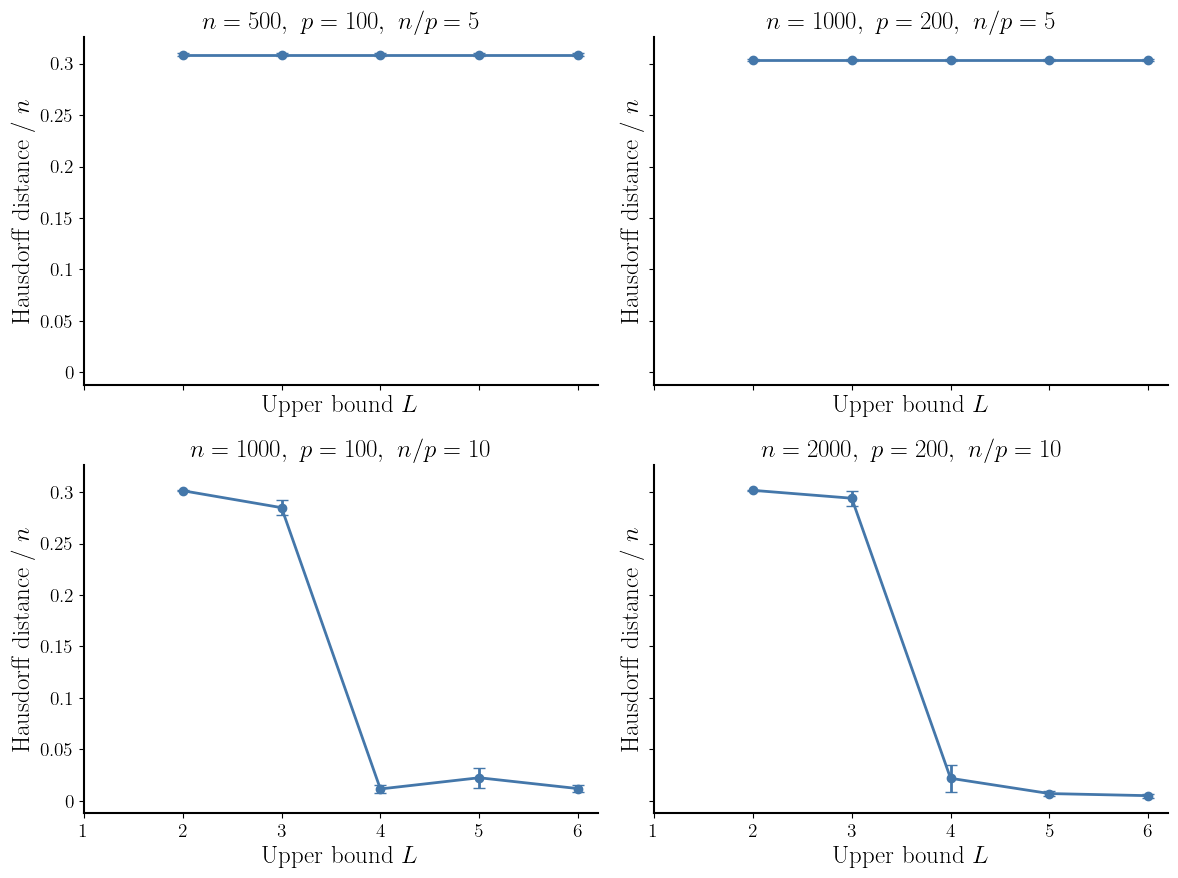

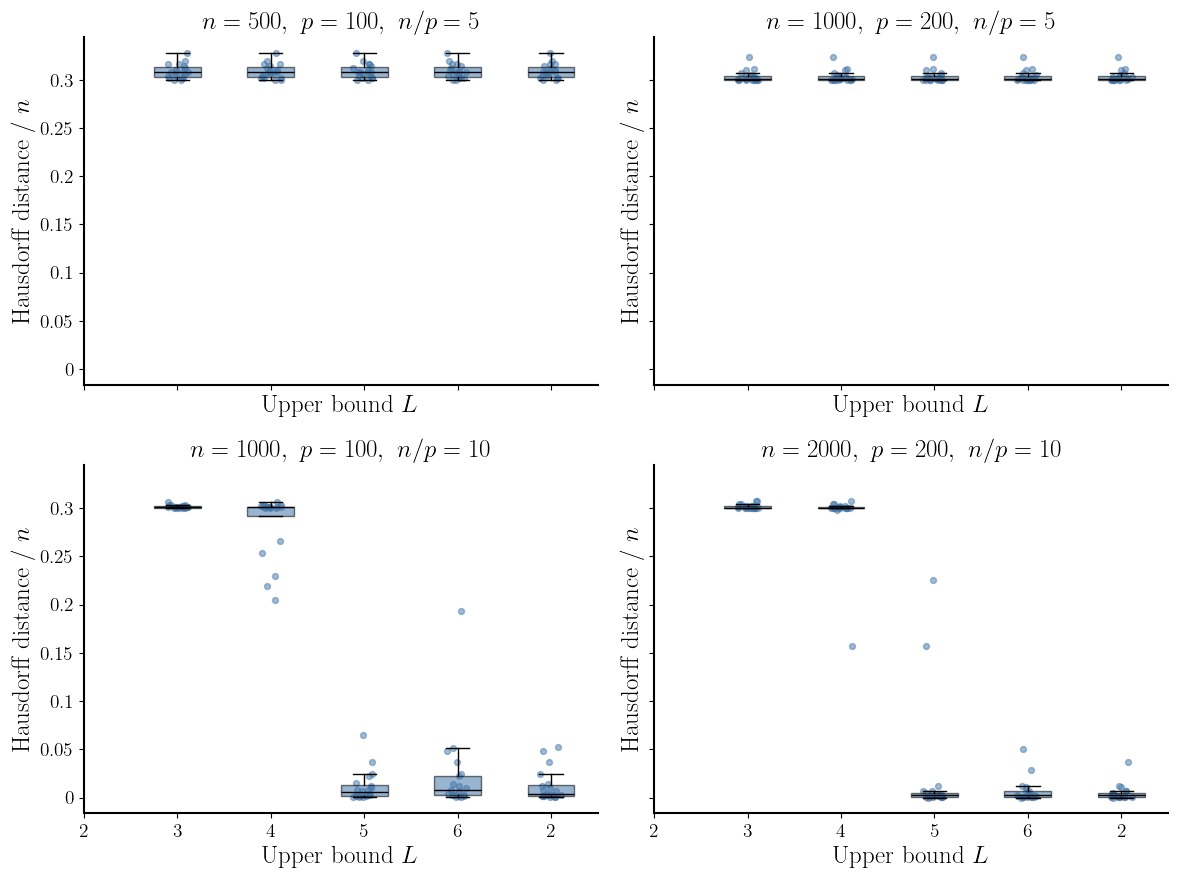

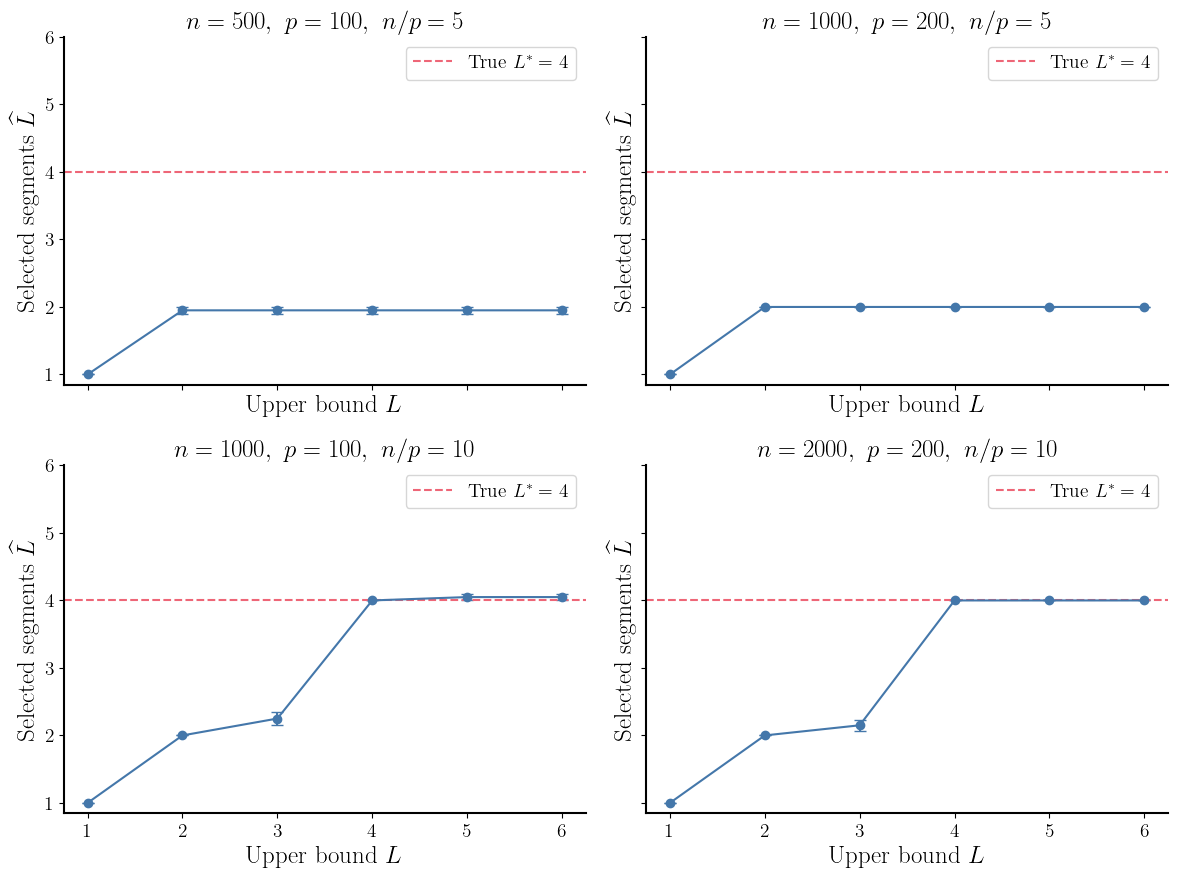

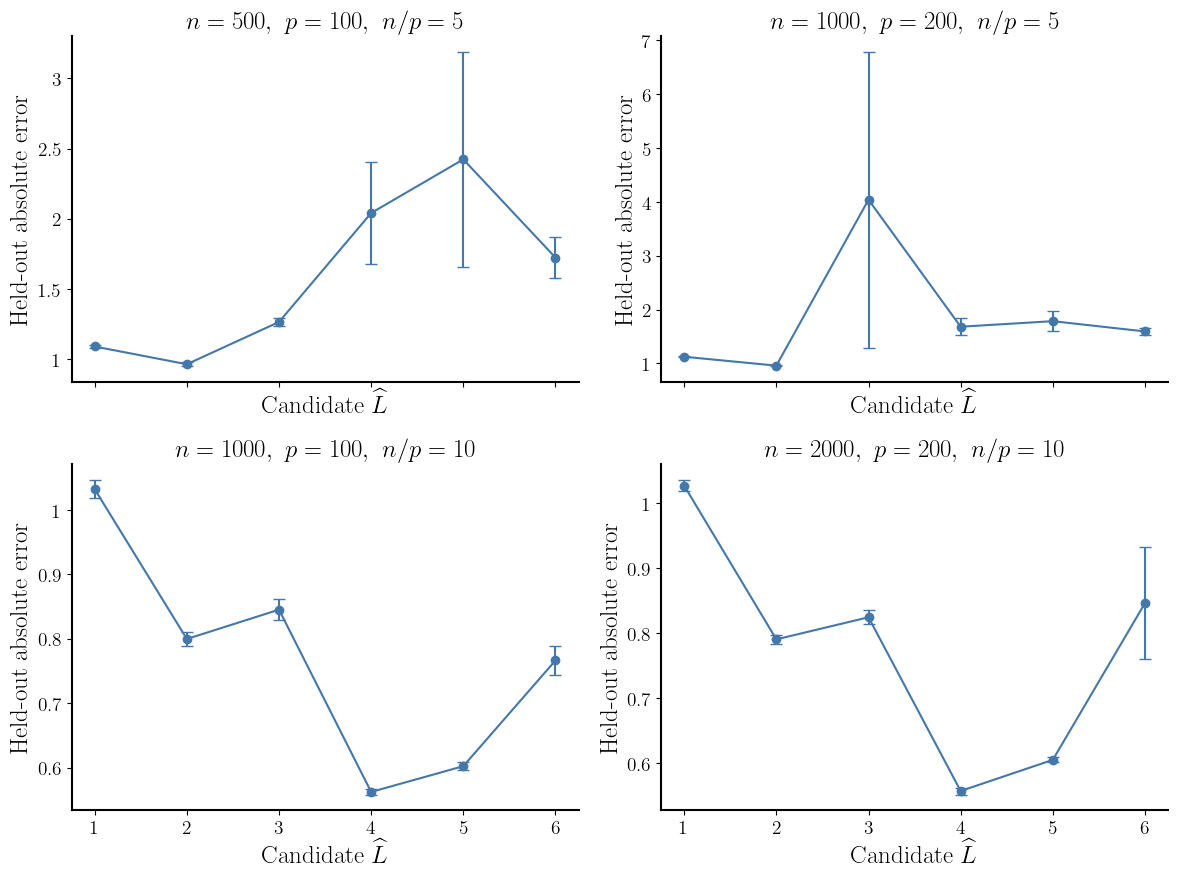

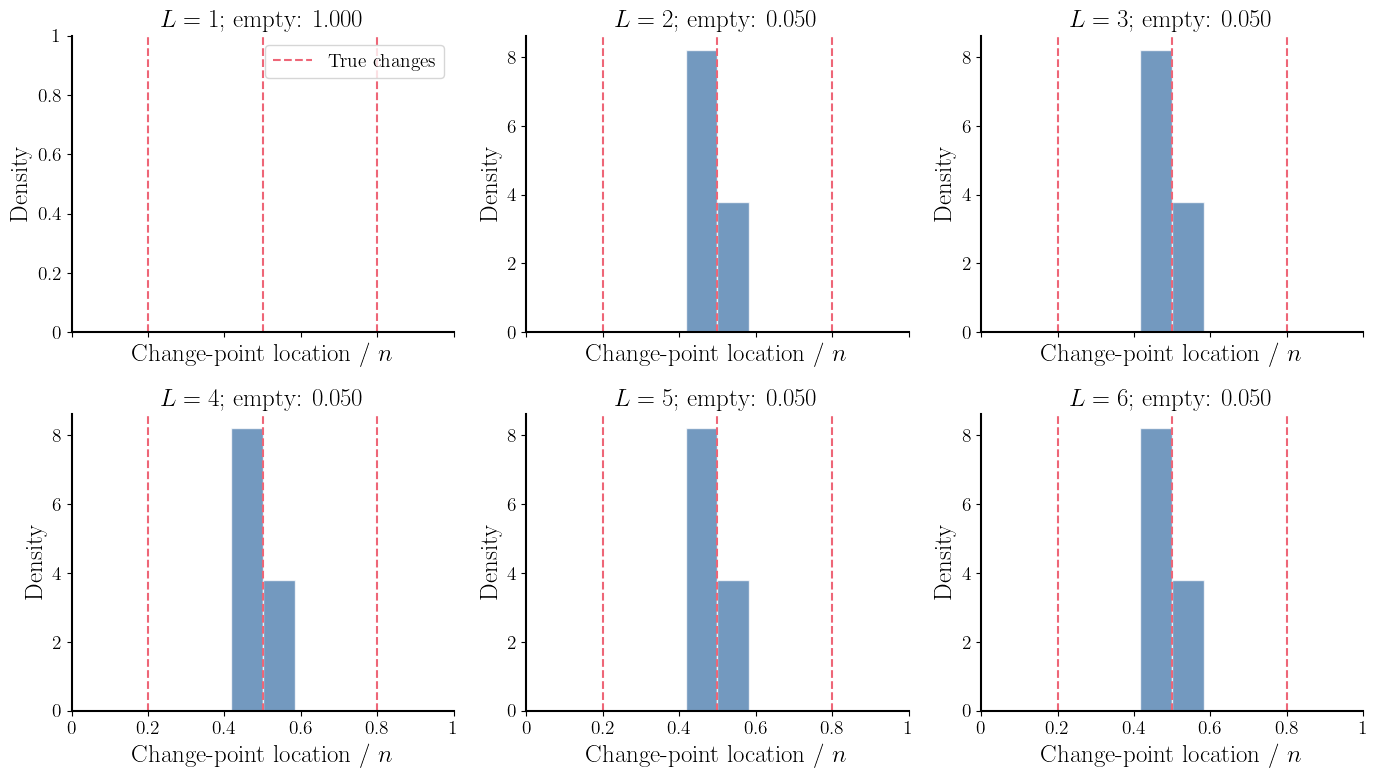

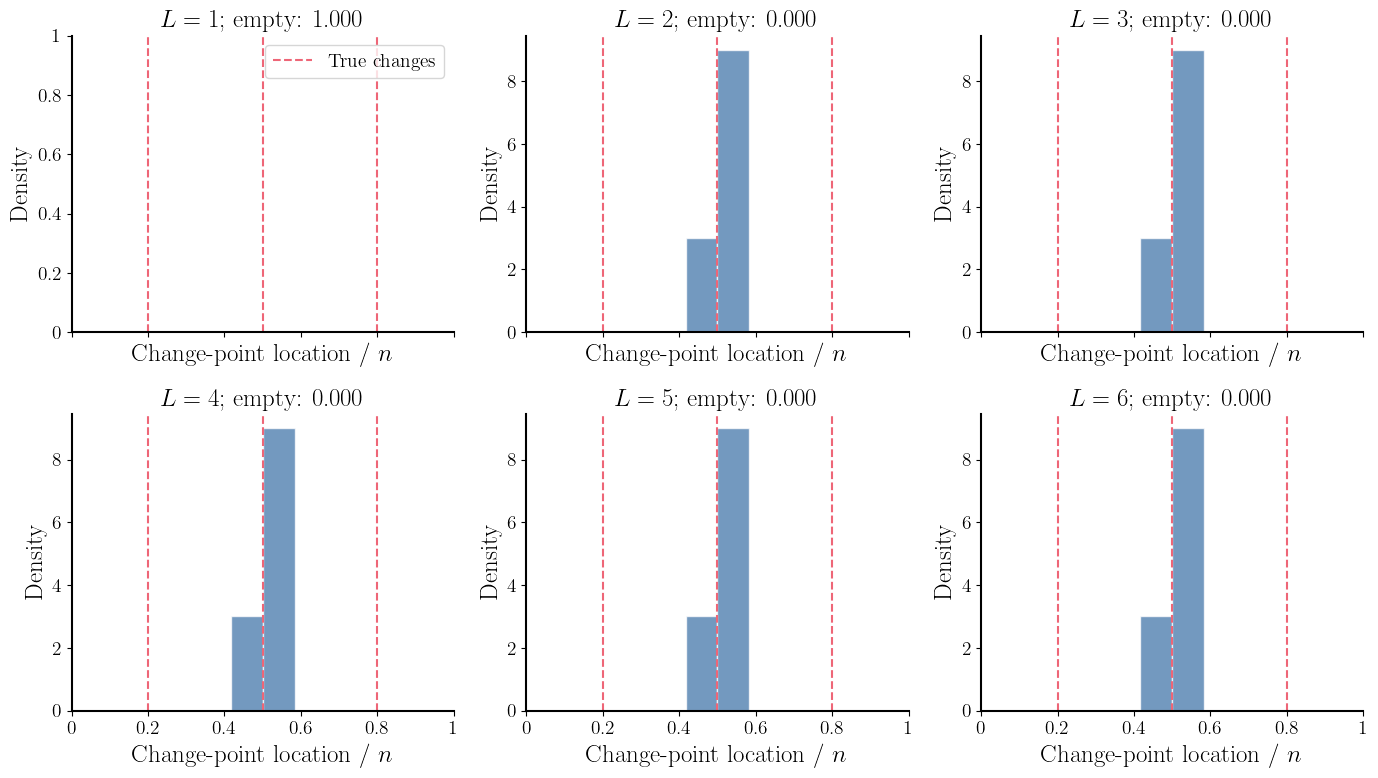

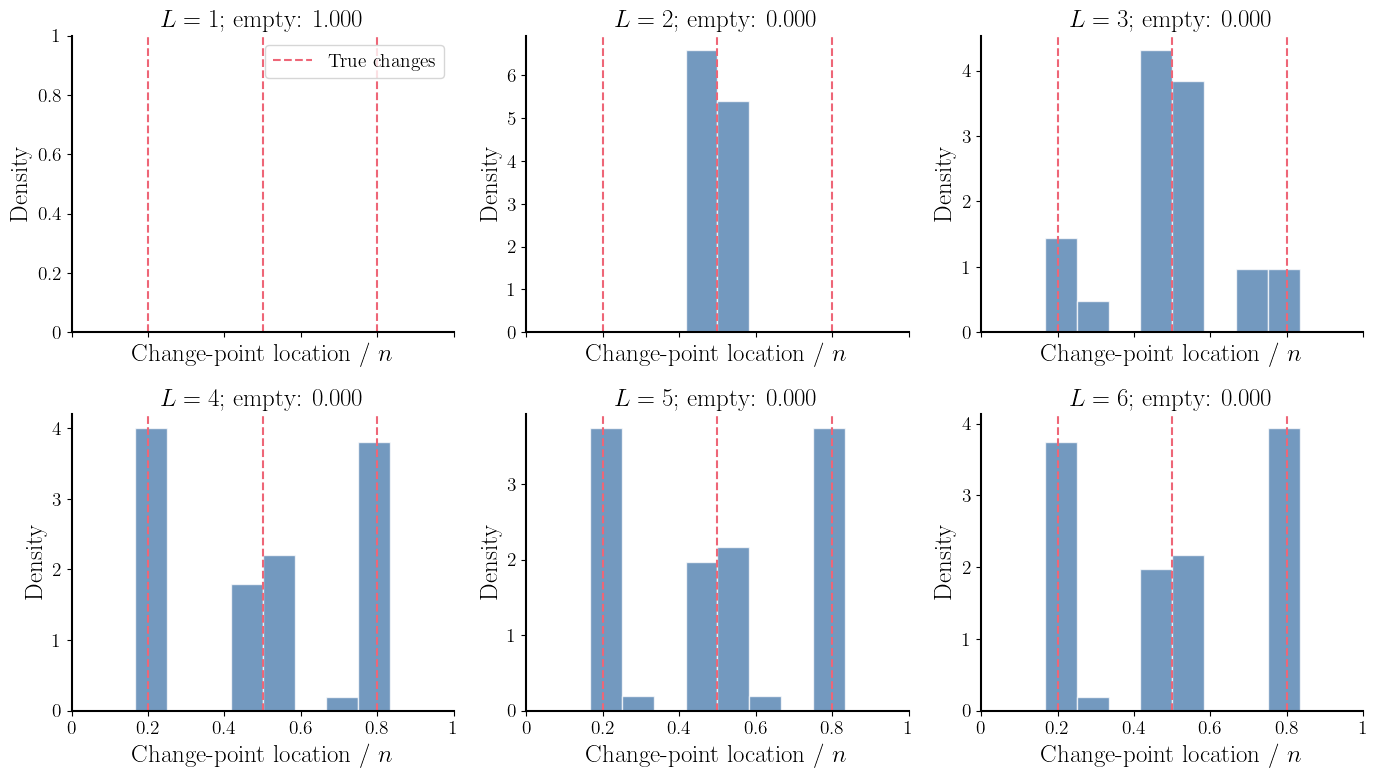

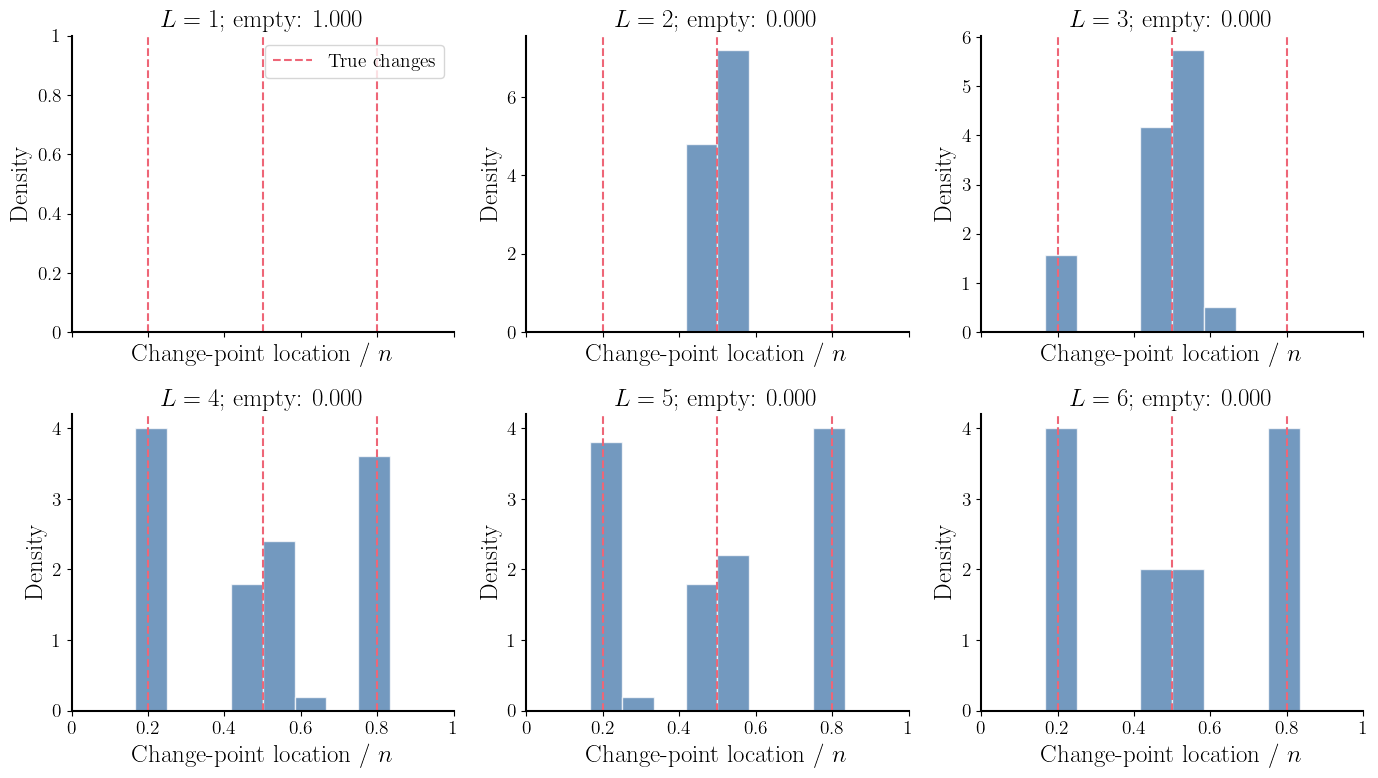

In [1]:
# SELF-CONTAINED plotting and diagnostic report; no setup cells required.
import os,pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter,MaxNLocator
plt.switch_backend('module://matplotlib_inline.backend_inline')
plt.rcParams.update({'font.family':'serif','font.serif':['Computer Modern Roman','Times New Roman','DejaVu Serif'],
    'text.usetex':True,'font.size':14,'axes.labelsize':18,'axes.titlesize':18,
    'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14,
    'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':1.5})
with Path('results/E_L_CV10_selfcontained_gap20/study.pkl').open('rb') as f:el_study=pickle.load(f)
EL_FIG=Path('figures');EL_FIG.mkdir(exist_ok=True)
EL_BLUE='#4477AA'; EL_TRUTH='#EE6677'
el_fmt=FuncFormatter(lambda value,pos:f'{value:.3f}'.rstrip('0').rstrip('.') if value else '0')
def el_finish(fig,name):
    fig.tight_layout()
    fig.savefig(EL_FIG/(name+'.pdf'),bbox_inches='tight')
    fig.savefig(EL_FIG/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

def el_groups(rows,key):return [np.array([r['fits'][u][key] for r in rows]) for u in range(1,7)]
print('All values below are computed from fresh independent trials with fold-local minimum gap n_train/20.')
print('n | p | n/p | upper L | mean selected segments | correct-count fraction | empty fraction | conditional Hausdorff/n')
for (n,p),rows in el_study['rows'].items():
    for u in range(1,7):
        fits=[r['fits'][u] for r in rows]
        finite=[f['haus'] for f in fits if np.isfinite(f['haus'])]
        print(f'{n} | {p} | {n/p:.3f} | {u} | {np.mean([f["selected"] for f in fits]):.3f} | '
              f'{np.mean([f["correct_count"] for f in fits]):.3f} | {np.mean([f["empty"] for f in fits]):.3f} | '
              +(f'{np.mean(finite):.3f}' if finite else 'undefined'))
    scores=np.array([r['fits'][6]['scores'] for r in rows])/n
    trace=rows[0]['trace']
    print('Candidate mean heldout absolute errors (K=1,...,6):',np.array2string(scores.mean(axis=0),precision=3))
    print('Trial 0: oracle true-boundary OLS heldout absolute error',f'{trace["oracle_absolute_mean"]:.3f}',
          '; true-coefficient noise baseline',f'{trace["known_beta_absolute_mean"]:.3f}',
          '; true-segment training sizes',trace['oracle_train_rows'][:4],
          '; ranks',trace['oracle_rank'][:4])
    candidate4=[v for v in trace['train_cp'] if v['K']==4]
    fold_haus=[]
    for fold,item in enumerate(candidate4):
        train=np.setdiff1d(np.arange(n),np.arange(fold,n,10))
        mapped=train[item['cp']]
        pair=np.abs(mapped[:,None]-rows[0]['truth'][None,:])/n
        fold_haus.append(max(pair.min(axis=0).max(),pair.min(axis=1).max()))
    print('Trial 0: actual K=4 heldout MAE',f'{rows[0]["fits"][6]["scores"][3]/n:.3f}',
          '; median K=4 fold location Hausdorff/n',f'{np.median(fold_haus):.3f}')
    # Report the actual hard-refit sample counts and coefficient sizes by candidate.
    offset=0
    for k in range(1,7):
        ref=trace['refits'][offset:offset+10*k];offset+=10*k
        print(f'  K={k}: segment-refit rows min/median/max '
              f'{min(r["rows"] for r in ref)}/{np.median([r["rows"] for r in ref]):.3f}/{max(r["rows"] for r in ref)}; '
              f'underdetermined fraction {np.mean([r["rows"]<p for r in ref]):.3f}; '
              f'median coefficient norm {np.median([r["norm"] for r in ref]):.3f}')

fig,axes=plt.subplots(2,2,figsize=(12,9),sharex=True,sharey=True)
for ax,((n,p),rows) in zip(axes.flat,el_study['rows'].items()):
    groups=el_groups(rows,'haus');means=[];ses=[]
    for group in groups:
        v=group[np.isfinite(group)]
        means.append(v.mean() if len(v) else np.nan)
        ses.append(v.std(ddof=1)/np.sqrt(len(v)) if len(v)>1 else np.nan)
    ax.errorbar(range(1,7),means,yerr=ses,color=EL_BLUE,marker='o',capsize=4,lw=2)
    ax.set_title(fr'$n={n},\ p={p},\ n/p={n/p:g}$')
    ax.set_xlabel(r'Upper bound $L$');ax.set_ylabel(r'Hausdorff distance / $n$')
    ax.set_xticks(range(1,7));ax.yaxis.set_major_formatter(el_fmt)
el_finish(fig,'E_L_CV10_gap20_size_ratio_location_mean_se')

fig,axes=plt.subplots(2,2,figsize=(12,9),sharex=True,sharey=True)
for ax,((n,p),rows) in zip(axes.flat,el_study['rows'].items()):
    rng=np.random.default_rng(42)
    for u,group in enumerate(el_groups(rows,'haus'),1):
        values=group[np.isfinite(group)]
        if len(values):
            ax.boxplot([values],positions=[u],widths=.5,showfliers=False,patch_artist=True,
                       boxprops={'facecolor':EL_BLUE,'alpha':.55},medianprops={'color':'black'})
            ax.scatter(u+rng.uniform(-.12,.12,len(values)),values,color=EL_BLUE,s=18,alpha=.5)
    ax.set_title(fr'$n={n},\ p={p},\ n/p={n/p:g}$');ax.set_xlabel(r'Upper bound $L$')
    ax.set_ylabel(r'Hausdorff distance / $n$');ax.set_xticks(range(1,7));ax.yaxis.set_major_formatter(el_fmt)
el_finish(fig,'E_L_CV10_gap20_size_ratio_location_boxplots')

fig,axes=plt.subplots(2,2,figsize=(12,9),sharex=True,sharey=True)
for ax,((n,p),rows) in zip(axes.flat,el_study['rows'].items()):
    counts=np.array([[r['fits'][u]['selected'] for u in range(1,7)] for r in rows])
    ax.errorbar(range(1,7),counts.mean(axis=0),yerr=counts.std(axis=0,ddof=1)/np.sqrt(len(rows)),color=EL_BLUE,marker='o',capsize=4)
    ax.axhline(4,color=EL_TRUTH,ls='--',label=r'True $L^*=4$')
    ax.set_title(fr'$n={n},\ p={p},\ n/p={n/p:g}$');ax.set_xlabel(r'Upper bound $L$')
    ax.set_ylabel(r'Selected segments $\widehat L$');ax.set_xticks(range(1,7));ax.set_yticks(range(1,7));ax.legend()
el_finish(fig,'E_L_CV10_gap20_size_ratio_selected_counts')

fig,axes=plt.subplots(2,2,figsize=(12,9),sharex=True)
for ax,((n,p),rows) in zip(axes.flat,el_study['rows'].items()):
    scores=np.array([r['fits'][6]['scores'] for r in rows])/n
    ax.errorbar(range(1,7),scores.mean(axis=0),yerr=scores.std(axis=0,ddof=1)/np.sqrt(len(rows)),color=EL_BLUE,marker='o',capsize=4)
    ax.set_title(fr'$n={n},\ p={p},\ n/p={n/p:g}$');ax.set_xlabel(r'Candidate $\widehat L$')
    ax.set_ylabel('Held-out absolute error');ax.set_xticks(range(1,7));ax.yaxis.set_major_formatter(el_fmt)
el_finish(fig,'E_L_CV10_gap20_size_ratio_cv_scores')

for (n,p),rows in el_study['rows'].items():
    fig,axes=plt.subplots(2,3,figsize=(14,8),sharex=True)
    for u,ax in enumerate(axes.flat,1):
        cp=np.concatenate([r['fits'][u]['cp'] for r in rows])/n
        if len(cp):ax.hist(cp,bins=np.linspace(0,1,13),density=True,color=EL_BLUE,alpha=.75,edgecolor='white')
        for index,truth in enumerate([.2,.5,.8]):ax.axvline(truth,color=EL_TRUTH,ls='--',lw=1.5,label='True changes' if index==0 else None)
        empty=np.mean([r['fits'][u]['empty'] for r in rows])
        ax.set_title(fr'$L={u}$; empty: {empty:.3f}');ax.set_xlabel('Change-point location / $n$')
        ax.set_ylabel('Density');ax.set_xlim(0,1);ax.xaxis.set_major_formatter(el_fmt);ax.yaxis.set_major_formatter(el_fmt)
        if u==1:ax.legend()
    el_finish(fig,f'E_L_CV10_gap20_n{n}_p{p}_changepoint_histograms')


<div style="color:#4477AA">

### Separate numerical issue: same selected count, different final refit

The native helper returns a fresh full-data fit after CV. The package's marginal-curve fitting includes random optimizer restarts. Its final refit inherits the RNG state left after evaluating the candidates, so changing the upper bound changes this initialization even when CV selects the same count.

We preserve the **actual native helper outputs** in all plots. Comparing upper bounds 4 and 6 among trials selecting the same count gives different final change-point locations in **3 of 19** trials at $(n,p)=(1000,100)$ and **3 of 20** at $(2000,200)$. Comparing upper bounds 5 and 6 gives different locations in **3 of 20** trials in each high-ratio setting. Both ratio-five settings have zero such differences.

Consequently, the small changes in Hausdorff error across upper bounds 4–6 must not be interpreted solely as an effect of the selected count. This is a numerical sensitivity in the shared implementation, distinct from the count-selection effect documented above.

The self-contained diagnostic below uses the representative $(n,p)=(2000,200)$ trial 2. Native calls select four segments at all three bounds, but return $[400,1000,1595]$ at bounds 4 and 5 and $[444,973,1527]$ at bound 6. Two additional exact-four-segment full-data refits with the **same** RNG initialization give bitwise-identical change points and prediction matrices. They are a reproducibility check only and are **not substituted** into the study, its summaries, or its figures. No library or gold-standard notebook is changed.

</div>

In [1]:
# SELF-CONTAINED diagnostic only; it does not replace any study results.
import os,pickle,random
from pathlib import Path
from contextlib import redirect_stdout,redirect_stderr
from io import StringIO
import numpy as np
import torch
from WERM.estimators import weighted_erm
n,p,trial,seed=2000,200,2,20261110
with Path('results/E_L_CV10_selfcontained_gap20/study.pkl').open('rb') as f:study=pickle.load(f)
row=study['rows'][(n,p)][trial]
assert all(row['fits'][u]['selected']==4 for u in [4,5,6])
rng=np.random.default_rng(np.random.SeedSequence([seed,n,p,trial]))
beta=np.empty((p,4));beta[:,0]=rng.normal(size=p)*np.sqrt(n/p)
for k in range(1,4):beta[:,k]=beta[:,k-1]+1.5*np.sqrt(n/p)*rng.normal(size=p)
X=rng.normal(size=(n,p))/np.sqrt(n)
truth=np.rint(n*np.array([.2,.5,.8])).astype(int)
state=np.searchsorted(truth,np.arange(n),side='right')
y=np.einsum('ij,ij->i',X,beta[:,state].T)+rng.normal(0,.5,n)
loss=lambda prediction,response:.5*(np.asarray(prediction)-np.asarray(response))**2
repeats=[]
for repeat in range(2):
    np.random.seed(seed+trial);torch.manual_seed(seed+trial);random.seed(seed+trial)
    with redirect_stdout(StringIO()),redirect_stderr(StringIO()):
        cp,B=weighted_erm(X=X,y=y,M=loss,L=4,Delta_n=n//20,gamma=0.,
            L_is_upper_bound=False,return_B_hat=True,
            coefficient_loss='least_squares',coefficient_penalty='none')
    repeats.append((np.asarray(cp,int),X@B))
np.testing.assert_array_equal(repeats[0][0],repeats[1][0])
np.testing.assert_array_equal(repeats[0][1],repeats[1][1])
print('Numerical-refit diagnostic only: n=2000, p=200, trial=2, selected K=4.')
for upper in [4,5,6]:
    print(f'Native helper upper L={upper}: CP={row["fits"][upper]["cp"].tolist()}; '
          f'Hausdorff/n={row["fits"][upper]["haus"]:.3f}')
print('Two exact-count final refits with identical RNG initialization:',repeats[0][0].tolist())
print('Their change points AND full fitted prediction matrices are bitwise identical.')
print('Native results above are retained; controlled refits are not substituted into the study or plots.')
with Path('results/E_L_CV10_selfcontained_gap20/refit_rng_diagnostic.pkl').open('wb') as f:
    pickle.dump(dict(n=n,p=p,trial=trial,seed=seed+trial,selected_K=4,
        native_cp={u:row['fits'][u]['cp'] for u in [4,5,6]},
        controlled_cp=repeats[0][0],repeated_cp_equal=True,repeated_predictions_equal=True),f)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/9880 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/9880 [00:00<?, ?it/s]

Numerical-refit diagnostic only: n=2000, p=200, trial=2, selected K=4.
Native helper upper L=4: CP=[400, 1000, 1595]; Hausdorff/n=0.003
Native helper upper L=5: CP=[400, 1000, 1595]; Hausdorff/n=0.003
Native helper upper L=6: CP=[444, 973, 1527]; Hausdorff/n=0.036
Two exact-count final refits with identical RNG initialization: [400, 1000, 1595]
Their change points AND full fitted prediction matrices are bitwise identical.
Native results above are retained; controlled refits are not substituted into the study or plots.


## Historical $\Delta_n=1$ investigations — superseded for the current Appendix G.6 study

These collapsed cells retain the previous experiments, their saved outputs, and both original user comments for provenance. **Use the self-contained second part above for the current study.** These historical cells use the earlier minimum-gap convention and are tagged `skip-execution`; they are not prerequisites for the new experiment.

<span style="color:#4477AA">**New Appendix G.6 extension: vary the upper bound (L)**</span>

The four cells above are the original fixed-working-(L) experiment and its plots. This extension keeps them intact. It follows the `weighted_erm_joint_cv` call pattern in the M1/M2 final notebooks: for each upper bound $L=1,\ldots,6$, 10 interleaved folds select one exact-count $\hat L\le L$ with **absolute held-out prediction error**, no coefficient penalty, and $P=0$. The chosen exact-count WERM model is then refit to all observations. Data generation, true $L^*=4$, and loss for fitting and partition search are unchanged from the original E-L experiment. The trial record includes each candidate's held-out score so repeated selections can be diagnosed.

In [ ]:
# Blue extension; original E-L cells above are unchanged.
from WERM.experiment_utils import weighted_erm_joint_cv
CV_UPPER_BOUNDS = np.arange(1, 7)
CV_UPPER_ARTIFACT = RESULTS_DIR / (
    'E_L_upperbound_goldCV10_100paired_seed20260916_smoke.pkl' if SMOKE_MODE
    else 'E_L_upperbound_goldCV10_100paired_seed20260916.pkl')
CV_UPPER_JOBS = 2 if SMOKE_MODE else int(os.environ.get('WERM_N_JOBS', '8'))
CV_SCORER = lambda prediction, truth: np.abs(np.asarray(prediction)-np.asarray(truth))

# What is the true number of segments L^* here? It should be L^* = 4. 

def run_upper_bound_cv_trial(trial):
    X, y, _, _ = make_paired_data(trial, TRUE_CP)
    fits = {}
    for upper in CV_UPPER_BOUNDS:
        # Same exact-count CV implementation and absolute scoring as M1/M2 final.
        (working_l, _), cp, diagnostic = weighted_erm_joint_cv(
            X, y, M, CV_SCORER, Lmax=int(upper),
            delta_fraction=1/50, absolute_delta_n=1,
            l1_constants=(0.0,), penalty_norm='none',
            coefficient_loss='least_squares',
            num_folds=10, n_jobs=1, return_diagnostics=True) # Are you sure you are using M_scorer as absolute loss here? Because that is what we expect to use, and what was used in M1, M2, M3. 
        fits[int(upper)] = dict(working_L=int(working_l), cp=np.asarray(cp, int),
                                cv_scores=np.asarray(diagnostic['scores'], float),
                                **error_metrics(cp, TRUE_CP))
        assert working_l <= upper and len(cp) == working_l-1
    # Each candidate's score is identical across larger upper-bound searches.
    for upper in CV_UPPER_BOUNDS[:-1]:
        np.testing.assert_allclose(fits[int(upper)]['cv_scores'],
                                   fits[int(upper+1)]['cv_scores'][:int(upper)])
    return fits

with parallel_config(backend='loky', inner_max_num_threads=1):
    cv_upper_trials = Parallel(n_jobs=CV_UPPER_JOBS, verbose=10)(
        delayed(run_upper_bound_cv_trial)(trial) for trial in range(N_TRIALS))
with CV_UPPER_ARTIFACT.open('wb') as handle:
    pickle.dump(dict(trials=cv_upper_trials,
                     params=dict(n=N, p=P, true_cp=TRUE_CP, true_L=TRUE_L,
                                 upper_bounds=CV_UPPER_BOUNDS,
                                 folds=10, cv_scorer='absolute error',
                                 fit_loss='half squared error',
                                 delta_n=DELTA_N, n_trials=N_TRIALS,
                                 seed=SEED)), handle)
print(f'Saved {len(cv_upper_trials)} paired upper-bound CV trials to {CV_UPPER_ARTIFACT}')


Saved 100 paired upper-bound CV trials to results/E_L_upperbound_goldCV10_100paired_seed20260916.pkl


<span style="color:#4477AA">**Upper-bound CV results**</span>

The original fixed-working-$L$ results above remain unchanged. With the M1/M2 final-notebook CV helper and absolute-error scoring, the 100 new paired trials selected \(\hat L=2\) in 99 trials for **every** upper bound from 2 through 6 (and \(\hat L=1\) in the other trial). The mean held-out scores for candidates \(\hat L=1,\ldots,6\) were 555.344, 481.605, 650.639, 1135.026, 962.799, and 876.068, respectively. Because the exact-count candidate score does not depend on the upper bound, the same winner remains selected as larger candidates are admitted. This is a substantive under-selection finding for this \(n=500,p=100\) setup, despite the original fixed-\(L\) localization being best at the true \(L^*=4\). The following plot shows both the selected counts and the held-out scores that cause the plateau.

A plausible cause is the validation refit: at the true partition, the first and last segments each have 100 observations, so a 10-fold training split leaves about 90 observations to fit 100 coefficients in those segments. This makes their unpenalized segmentwise least-squares refits underdetermined. The score table exposes that behavior rather than treating a flat result as a plotting error.

Upper L | selected L-hat distribution | mean conditional Hausdorff | mean unconditional loss
1 | {1: 100} | undefined | 1.250
2 | {1: 1, 2: 99} | 0.310 | 0.283
3 | {1: 1, 2: 99} | 0.310 | 0.283
4 | {1: 1, 2: 99} | 0.310 | 0.283
5 | {1: 1, 2: 99} | 0.310 | 0.283
6 | {1: 1, 2: 99} | 0.310 | 0.283
Mean held-out absolute-error score by exact-count candidate: {1: 555.344, 2: 481.605, 3: 650.639, 4: 1135.026, 5: 962.799, 6: 876.068}


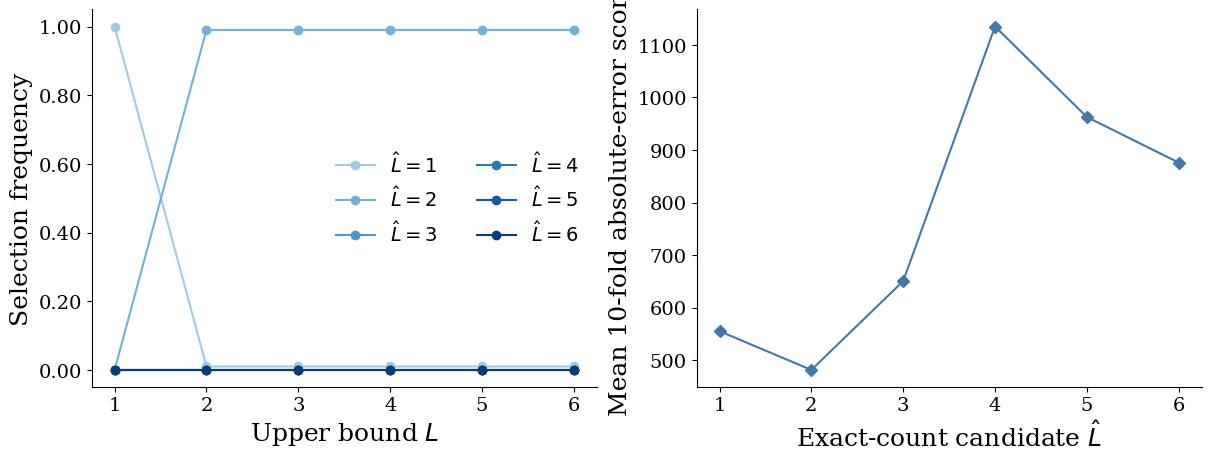

In [1]:
# Plot only: rerunning this cell reads the completed artifact.
import pickle
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
CV_UPPER_ARTIFACT = Path('results') / (
    'E_L_upperbound_goldCV10_100paired_seed20260916_smoke.pkl' if os.environ.get('WERM_SMOKE') == '1'
    else 'E_L_upperbound_goldCV10_100paired_seed20260916.pkl')
with CV_UPPER_ARTIFACT.open('rb') as handle:
    cv_upper_payload = pickle.load(handle)
cv_upper_trials = cv_upper_payload['trials']
upper = np.asarray(cv_upper_payload['params']['upper_bounds'])
selected = np.asarray([[trial[int(L)]['working_L'] for L in upper] for trial in cv_upper_trials])
haus = np.asarray([[trial[int(L)]['conditional_haus'] for L in upper] for trial in cv_upper_trials])
loss = np.asarray([[trial[int(L)]['unconditional_loss'] for L in upper] for trial in cv_upper_trials])
cv_scores = np.asarray([trial[int(upper[-1])]['cv_scores'] for trial in cv_upper_trials])
print('Upper L | selected L-hat distribution | mean conditional Hausdorff | mean unconditional loss')
for j,L in enumerate(upper):
    counts = {int(k): int(v) for k, v in zip(*np.unique(selected[:,j],return_counts=True))}
    finite = haus[:,j][np.isfinite(haus[:,j])]
    h = f'{finite.mean():.3f}' if len(finite) else 'undefined'
    print(f'{L} | {counts} | {h} | {loss[:,j].mean():.3f}')
print('Mean held-out absolute-error score by exact-count candidate:',
      {int(L): round(float(value),3) for L,value in zip(upper,cv_scores.mean(axis=0))})
plt.rcParams.update({'font.family':'serif','font.size':14,'axes.labelsize':18,
                     'axes.titlesize':18,'xtick.labelsize':14,'ytick.labelsize':14,
                     'legend.fontsize':14,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for working_l in upper:
    axes[0].plot(upper,np.mean(selected==working_l,axis=0),marker='o',
                 color=plt.cm.Blues(.25+.7*working_l/len(upper)),
                 label=rf'$\hat L={working_l}$')
axes[0].set(xlabel=r'Upper bound $L$',ylabel='Selection frequency')
axes[0].set_xticks(upper);axes[0].yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
axes[0].legend(frameon=False,ncol=2)
mean_score=np.mean(cv_scores,axis=0)
axes[1].plot(upper,mean_score,color='#4477AA',marker='D')
axes[1].set(xlabel=r'Exact-count candidate $\hat L$',ylabel='Mean 10-fold absolute-error score')
axes[1].set_xticks(upper)
figure_path = Path('figures') / 'E_L_upperbound_CV10.pdf'
figure_path.parent.mkdir(exist_ok=True)
fig.savefig(figure_path)
plt.show()


<span style="color:#4477AA">**NEW — Review of the two CV implementation comments (Appendix G.6)**</span>

**True signal count.** Yes, $L^*=4$: the original setup defines `TRUE_CP = [100, 250, 400]` and `TRUE_L = len(TRUE_CP) + 1`. The four true segments have lengths 100, 150, 150, and 100. Every upper bound uses that same four-segment data-generating model; changing `Lmax` changes the allowed candidate counts, not the truth. The estimator receives the observations and candidate upper bound; it is not given the true change points.

**Validation loss.** Yes, the held-out scorer is absolute loss. In the existing call, `CV_SCORER` is the fourth positional argument of `weighted_erm_joint_cv`, whose fourth parameter is `M_scorer`. It is defined as `abs(prediction - truth)`. Least squares is used for fitting candidate segmentations and training-fold segment coefficients; validation scores sum absolute prediction errors on the held-out observations. The helper uses the same interleaved fold construction as the final M1/M2 experiments. The original E-L minimum-gap setting $\Delta_n=1$ is retained.

The executed audit below repeats trial 0 with **explicit `M_scorer=` syntax**, traces every scorer call, and independently sums the actual absolute residuals. It checks all six saved candidate scores and the saved selected change points. The half-squared residual totals are printed only as a diagnostic contrast and are not used for selection. The two comments in the earlier cell are preserved.

In [9]:
# Audit the user's two questions without changing the earlier experiment cells.
# Uses the existing E-L setup and CV_SCORER definitions above.
import inspect,pickle
from pathlib import Path
import numpy as np
from WERM.experiment_utils import weighted_erm_joint_cv

assert TRUE_L == 4 and len(TRUE_CP)==3
np.testing.assert_array_equal(TRUE_CP,np.array([100,250,400]))
X_audit,y_audit,beta_audit,state_audit=make_paired_data(0,TRUE_CP)
assert beta_audit.shape==(P,4)
np.testing.assert_array_equal(np.unique(state_audit),np.arange(4))
segment_sizes=np.bincount(state_audit,minlength=4)
# The original fourth positional argument really is M_scorer.
bound=inspect.signature(weighted_erm_joint_cv).bind_partial(X_audit,y_audit,M,CV_SCORER)
assert bound.arguments['M_scorer'] is CV_SCORER
np.testing.assert_allclose(CV_SCORER(np.array([2.,-3.]),np.zeros(2)),[2.,3.])
residuals=[]
def traced_absolute_scorer(prediction,truth):
    residual=np.asarray(prediction)-np.asarray(truth)
    value=CV_SCORER(prediction,truth)
    np.testing.assert_allclose(value,np.abs(residual),rtol=0,atol=0)
    residuals.extend(residual.reshape(-1).tolist())
    return value

(audit_K,_),audit_cp,audit_diagnostic=weighted_erm_joint_cv(
    X=X_audit,y=y_audit,M=M,M_scorer=traced_absolute_scorer,
    Lmax=6,delta_fraction=1/50,absolute_delta_n=1,
    l1_constants=(0.,),penalty_norm='none',coefficient_loss='least_squares',
    num_folds=10,n_jobs=1,standardize_y=False,
    selection_strategy='exhaustive',return_diagnostics=True)
assert audit_diagnostic['candidate_fold_fits']==6*10
# Exhaustive n_jobs=1 evaluation visits each candidate's ten folds in order.
assert len(residuals)==6*N
residuals=np.asarray(residuals).reshape(6,N)
absolute_totals=np.abs(residuals).sum(axis=1)
half_squared_totals=.5*np.square(residuals).sum(axis=1)
np.testing.assert_allclose(absolute_totals,audit_diagnostic['scores'],rtol=1e-12,atol=1e-10)
assert not np.allclose(half_squared_totals,audit_diagnostic['scores'])
with (Path('results')/'E_L_upperbound_goldCV10_100paired_seed20260916.pkl').open('rb') as f:
    saved_audit_payload=pickle.load(f)
assert saved_audit_payload['params']['true_L']==4
np.testing.assert_allclose(audit_diagnostic['scores'],saved_audit_payload['trials'][0][6]['cv_scores'],rtol=1e-7,atol=1e-7)
np.testing.assert_array_equal(audit_cp,saved_audit_payload['trials'][0][6]['cp'])
print(f'True number of segments: {TRUE_L}; true changes: {TRUE_CP.tolist()}')
print(f'True segment sizes: {segment_sizes.tolist()}')
print(f'Actual absolute-loss scorer calls: {len(residuals.ravel())}; candidate-fold fits: {audit_diagnostic["candidate_fold_fits"]}')
print('Candidate L-hat | actual absolute-error CV sum | half-squared sum on the same residuals (not used)')
for K,absolute,squared in zip(range(1,7),absolute_totals,half_squared_totals):
    print(f'{K} | {absolute:.3f} | {squared:.3f}')
print(f'Selected L-hat={audit_K}; change points={audit_cp.tolist()}; saved trial reproduced.')
with (Path('results')/'E_L_upperbound_CV10_scorer_audit.pkl').open('wb') as f:
    pickle.dump(dict(true_L=TRUE_L,true_cp=TRUE_CP,segment_sizes=segment_sizes,
        absolute_scores=absolute_totals,half_squared_scores_not_used=half_squared_totals,
        scorer_calls=len(residuals.ravel()),candidate_fold_fits=audit_diagnostic['candidate_fold_fits'],
        selected_L=audit_K,selected_cp=audit_cp),f)


True number of segments: 4; true changes: [100, 250, 400]
True segment sizes: [100, 150, 150, 100]
Actual absolute-loss scorer calls: 3000; candidate-fold fits: 60
Candidate L-hat | actual absolute-error CV sum | half-squared sum on the same residuals (not used)
1 | 628.440 | 644.894
2 | 522.462 | 423.188
3 | 568.853 | 506.597
4 | 978.467 | 3457.701
5 | 805.950 | 2566.131
6 | 733.613 | 994.874
Selected L-hat=2; change points=[237]; saved trial reproduced.


<span style="color:#4477AA">**NEW — Original-style upper-bound sensitivity figures**</span>

For Appendix G.6, “Sensitivity to number of change points,” these figures reproduce the earlier cells' three formats: mean normalized Hausdorff distance with standard-error bars, trial-level jittered boxplots, and change-point location histograms. The horizontal parameter is now the upper bound $L$, with the working count chosen by 10-fold CV. Hausdorff summaries condition on nonempty estimates; $L=1$ has no defined conditional distance. Histogram panels pool estimated change points and mark the three true locations by dashed lines. The repeated panels at bounds 2–6 reflect the saved CV selections, rather than duplicated plotting inputs.

Upper L | mean / median conditional Hausdorff | nonempty trials | empty rate
1 | undefined | 0/100 | 1.000
2 | 0.310 / 0.304 | 99/100 | 0.010
3 | 0.310 / 0.304 | 99/100 | 0.010
4 | 0.310 / 0.304 | 99/100 | 0.010
5 | 0.310 / 0.304 | 99/100 | 0.010
6 | 0.310 / 0.304 | 99/100 | 0.010


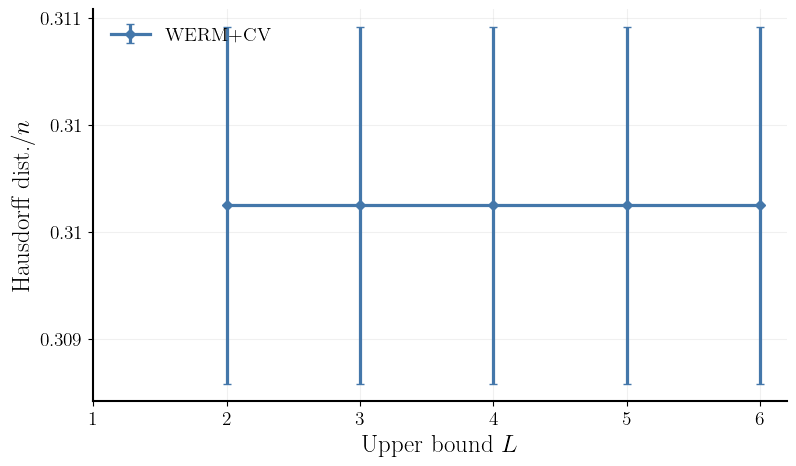

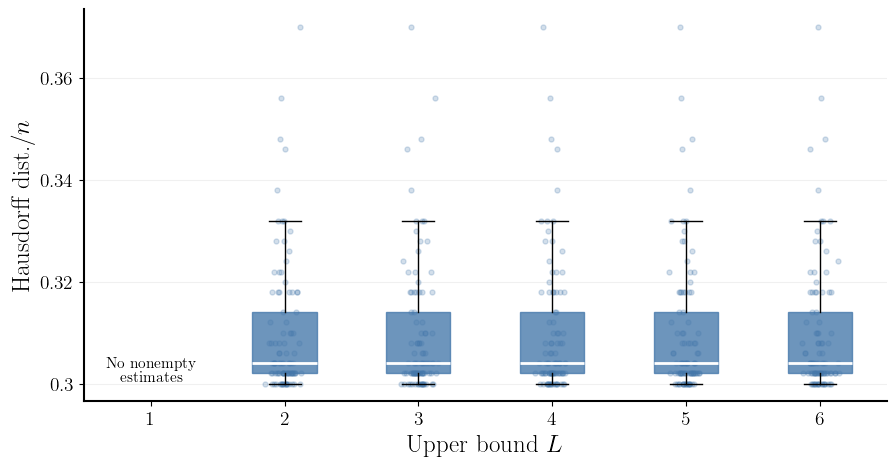

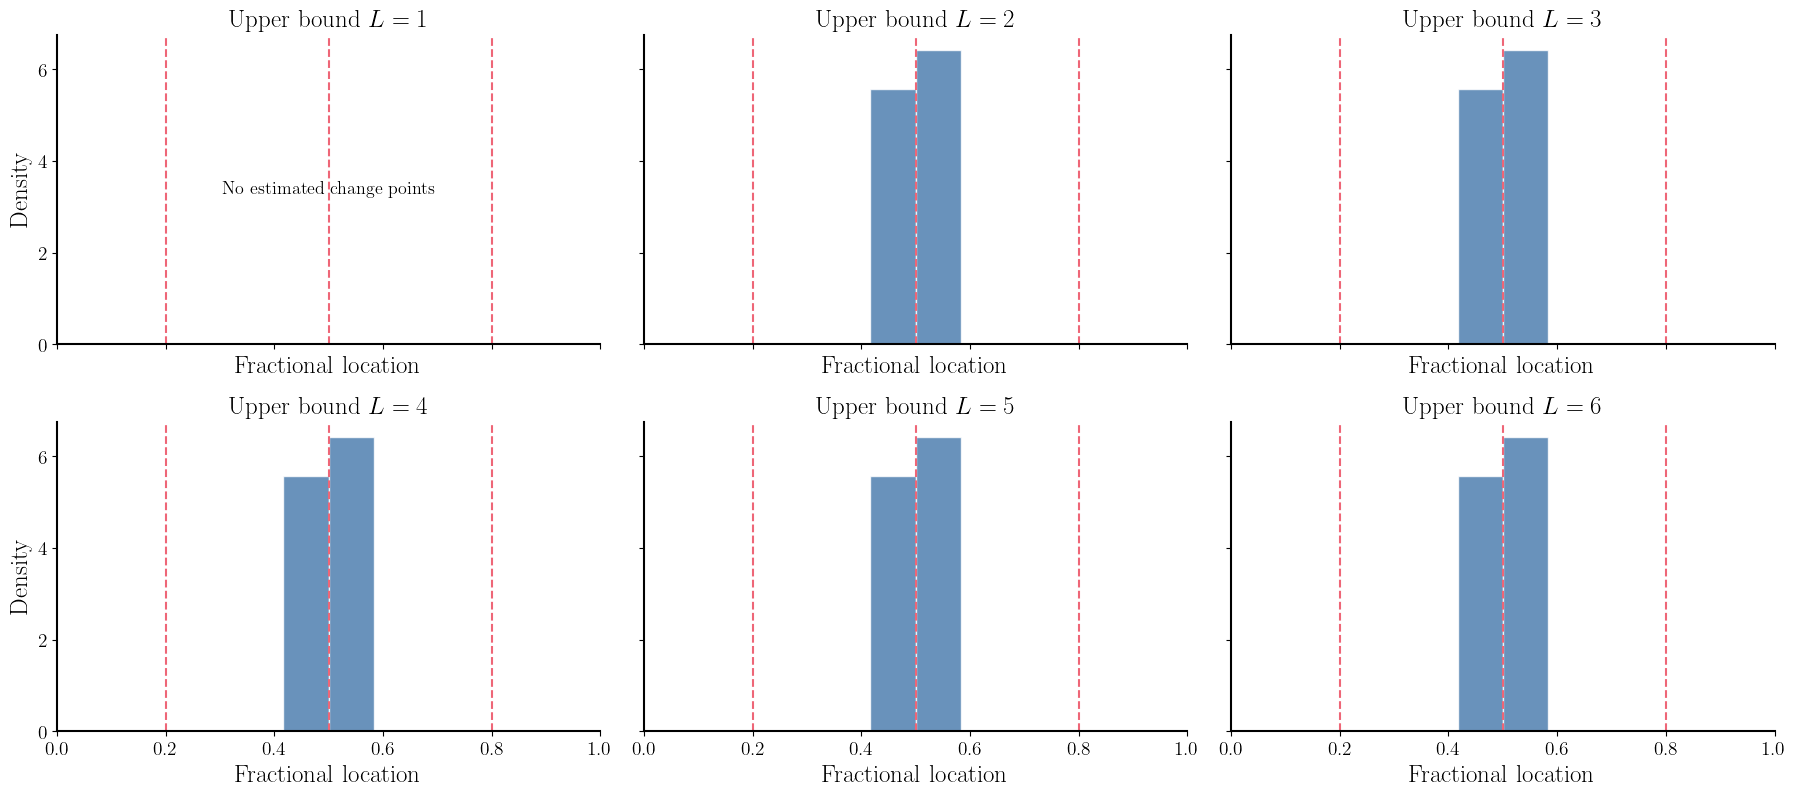

In [11]:
# Plot only: same mean/SE, jitter-boxplot, and location-histogram formats as the original E-L cells.
import os,pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator,FuncFormatter
path=Path('results')/('E_L_upperbound_goldCV10_100paired_seed20260916_smoke.pkl' if os.environ.get('WERM_SMOKE')=='1' else 'E_L_upperbound_goldCV10_100paired_seed20260916.pkl')
with path.open('rb') as f:el_cv=pickle.load(f)
trials=el_cv['trials'];params=el_cv['params'];upper=np.asarray(params['upper_bounds'])
n=params['n'];truth=np.asarray(params['true_cp'])
H=np.array([[r[int(L)]['conditional_haus'] for L in upper] for r in trials])
K=np.array([[r[int(L)]['working_L'] for L in upper] for r in trials])
plt.rcParams.update({'font.family':'serif','font.serif':['Computer Modern Roman','Times New Roman','DejaVu Serif'],
    'text.usetex':True,'font.size':14,'axes.labelsize':18,'axes.titlesize':18,'axes.linewidth':1.5,
    'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':14,'lines.linewidth':3,
    'lines.markersize':8,'axes.spines.top':False,'axes.spines.right':False})
fmt=FuncFormatter(lambda x,pos:f'{x:.3f}'.rstrip('0').rstrip('.') if abs(x)>1e-12 else '0')
figdir=Path('figures');figdir.mkdir(exist_ok=True)
suffix='_smoke' if os.environ.get('WERM_SMOKE')=='1' else ''

def el_mean_se(values):
    finite=np.isfinite(values);count=finite.sum(axis=0)
    mean=np.divide(np.nansum(values,axis=0),count,out=np.full(values.shape[1],np.nan),where=count>0)
    centered=np.where(finite,values-mean,0)
    sd=np.sqrt(np.divide((centered**2).sum(axis=0),np.maximum(count-1,1)))
    se=np.divide(sd,np.sqrt(count),out=np.zeros_like(sd),where=count>0)
    return mean,se

mean,se=el_mean_se(H)
print('Upper L | mean / median conditional Hausdorff | nonempty trials | empty rate')
for j,L in enumerate(upper):
    finite=H[:,j][np.isfinite(H[:,j])]
    location=f'{finite.mean():.3f} / {np.median(finite):.3f}' if len(finite) else 'undefined'
    print(f'{L} | {location} | {len(finite)}/{len(trials)} | {np.mean(K[:,j]==1):.3f}')
fig,ax=plt.subplots(figsize=(8,4.7))
ax.errorbar(upper,mean,yerr=se,color='#4477AA',marker='D',linestyle='-',linewidth=2.3,markersize=5,capsize=3,label='WERM+CV')
ax.set(xlabel=r'Upper bound $L$',ylabel=r'Hausdorff dist./$n$',xticks=upper)
ax.grid(alpha=.18);ax.yaxis.set_major_locator(MaxNLocator(4));ax.yaxis.set_major_formatter(fmt)
ax.legend(frameon=False)
fig.tight_layout(pad=.6)
fig.savefig(figdir/f'E_L_upperbound_CV10_location_mean_se{suffix}.pdf')
plt.show()

fig,ax=plt.subplots(figsize=(9,4.7));rng=np.random.default_rng(2901)
clean=[H[:,j][np.isfinite(H[:,j])] for j in range(len(upper))]
for position,values in zip(upper,clean):
    if len(values):ax.scatter(rng.normal(position,.055,len(values)),values,s=13,alpha=.23,color='#4477AA',zorder=2)
bp=ax.boxplot([g if len(g) else [np.nan] for g in clean],positions=upper,widths=.48,patch_artist=True,
    showfliers=False,medianprops=dict(color='white',linewidth=2))
for patch in bp['boxes']:patch.set(facecolor='#4477AA',edgecolor='#4477AA',alpha=.78)
ax.set(xlabel=r'Upper bound $L$',ylabel=r'Hausdorff dist./$n$',xticks=upper)
ax.grid(axis='y',alpha=.18);ax.yaxis.set_major_locator(MaxNLocator(4));ax.yaxis.set_major_formatter(fmt)
ax.text(1,.04,'No nonempty\nestimates',ha='center',va='bottom',transform=ax.get_xaxis_transform(),fontsize=11)
fig.tight_layout(pad=.6)
fig.savefig(figdir/f'E_L_upperbound_CV10_location_boxplots{suffix}.pdf')
fig.savefig(figdir/f'E_L_upperbound_CV10_location_boxplots{suffix}.png',dpi=160)
plt.show()

fig,axes=plt.subplots(2,3,figsize=(18,8),sharex=True,sharey=True)
for ax,L in zip(axes.flat,upper):
    points=np.concatenate([np.asarray(r[int(L)]['cp'])/n for r in trials])
    if len(points):ax.hist(points,bins=12,range=(0,1),density=True,color='#4477AA',edgecolor='white',alpha=.8)
    else:ax.text(.5,.5,'No estimated change points',transform=ax.transAxes,ha='center',va='center',fontsize=13)
    for cp in truth/n:ax.axvline(cp,color='#EE6677',linestyle='--',linewidth=1.5)
    ax.set_title(rf'Upper bound $L={L}$');ax.set_xlabel('Fractional location');ax.set_xlim(0,1)
    ax.yaxis.set_major_locator(MaxNLocator(4));ax.yaxis.set_major_formatter(fmt)
axes[0,0].set_ylabel('Density');axes[1,0].set_ylabel('Density')
fig.tight_layout(pad=.6,w_pad=1.,h_pad=1.)
fig.savefig(figdir/f'E_L_upperbound_CV10_changepoint_histograms{suffix}.pdf')
fig.savefig(figdir/f'E_L_upperbound_CV10_changepoint_histograms{suffix}.png',dpi=160)
plt.show()
